In [1]:
import time
import h5py
import shutil
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
import yaml
from scipy import stats as st
import gc
import resource


# integrated data imports
sys.path.append('/sdf/home/j/jwang343/rix101231825_Fe_L_edge/results/Jeff/DataAcceleratorChemRIXS/src/')
from chemrixs.average import Average
from chemrixs.smalldata import SmallData
from chemrixs.process import Reduced
from chemrixs.integrating_raw import SmallDataRaw
from chemrixs.utils import *
from pathlib import Path


### Load in desired keys for h5 and yaml files
- APD and FIM can use h5 directly
- Transmission and SVLS can use integrating so have energy specification

In [15]:
base = '/sdf/data/lcls/ds/rix/'
exp  = 'rix101231825'
run  = 120
fyaml = '../roi_input.yml'        
mono_yaml = '../mono_calib.yml'                

fname = f'{base}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5' 

runs_with_andor = [61, 62, 63, 64, 65, 66, 67, 68, 69, 71, 72, 73, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84]

# extract detector data directly from h5 file
with h5py.File(fname, 'r') as h5:
    g       = h5['intg/axis_svls']
    count   = g['count'][:].squeeze()
    event_codes = g['timing_sum_eventcodes'][:]
    light_status = g['lightStatus_sum_laser'][:]
    monoenc = g['mono_hrencoder_sum_value'][:].squeeze()
    fim0_wf = g['det_rix_fim0_sum_full_area'][:]
    fim1_wf = g['det_rix_fim1_sum_full_area'][:]
    svls_proj = g['droplet_dense_curve_corr_pj_ax_1_data'][:]
    print(svls_proj.shape)
    

    apd_wf = g['det_crix_w8_sum_full_area'][:]
    fzp = g['fzp_piranha_sum_full_area'][:]
    if run in runs_with_andor:
        andor_full = h5['intg/andor_dir/full_area'][:]
    
    epics = h5['epics_archiver']
    mono_premirror_pitch = epics['SP1K1_MONO_MMS_M_PI.RBV'][:]


mono_runs=[112,114,115,116,117,118,119,120,121,122,123,127,129,138,139,140,141,143,145]
    
# yaml file
with open(fyaml) as f:
    cfg = yaml.safe_load(f)
fim0_cfg = cfg['fim0']
fim1_cfg = cfg['fim1']
apd_cfg = cfg['apd']
fzp_cfg = cfg['fzp']
bins_cfg = cfg['bins']
evc_cfg = cfg['evc']
mono_cfg = cfg['mono_calib']


## SVLS processing yaml values
offset_roi = cfg['svls']['offset_roi']
thresh_min = cfg['svls']['threshold'][0]
thresh_max = cfg['svls']['threshold'][1]


base = '/sdf/data/lcls/ds/rix/'
exp  = 'rix101231825'
bg_run  = 86
bg_fyaml = '../BGroi_input.yml'                        

bg_fname = f'{base}/{exp}/hdf5/smalldata/{exp}_Run{bg_run:04d}.h5' 

# yaml file
with h5py.File(bg_fname, 'r') as h5:
    g       = h5['intg/axis_svls']
    bg_svls = g['droplet_dense_curve_corr_pj_ax_1_data'][:]
    



# process the runs so that i am able to get mono scan var
small_data = SmallDataRaw(fname, fyaml)
intg = small_data.integrating
print(dir(intg.axis_svls))
# svls_proj = intg.axis_svls.full_area
mono = intg.axis_svls.mono

(28931, 796)
120
setting up properties
dataset prop <functools.cached_property object at 0x7f1d4fefc890>
dataset prop <functools.cached_property object at 0x7f1d4fefc790>
dataset prop <functools.cached_property object at 0x7f1da68b4190>
dataset prop <functools.cached_property object at 0x7f1c95725fd0>
dataset prop <functools.cached_property object at 0x7f1d500dcad0>
dataset prop <functools.cached_property object at 0x7f1d500dcc50>
dataset prop <functools.cached_property object at 0x7f1d500dd310>
dataset prop <functools.cached_property object at 0x7f1c955a0510>
dataset prop <functools.cached_property object at 0x7f219c2f5610>
[IntegratingRaw] axis_svls: expected count = 335, 13352/28931 frames flagged by countmask (KEPT -- no frames removed)
['I0', '__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', 

### Manually calculate the mono energy array

In [2]:
# check to see what mono encoder returns
def get_mono(mono_encoder, mono_cfg, run_num, count):
    
    if len(mono_cfg) != 0:
        mono_calib_coeff=[]
        # NOTE: loop through all mono calibration configurations, for example:
        # run 1 - 81, 82 - 150, 151 - 253. then iterator would be range(3)
        for mono_config in mono_cfg:
            if (run_num>=mono_config[0]) and (run_num<=mono_config[1]):
                mono_calib_coeff = mono_config[2:4]
                
        # with the coefficients, calculate the shot to shot incident energy
        # with expected count
        expected_count = st.mode(count, keepdims=False)[0]
        hrencoder = mono_encoder/expected_count
        
        # # with normal count
        # hrencoder = getattr(det,'mono_encoder')/getattr(det,'count')
        
        tmp = np.polyval(mono_calib_coeff,hrencoder)
        premirror = 143088.0 # got this from a smalldata run, only works for day 2 runs
        mono = mono_energy(tmp,premirror)
        return mono


### Despeckle function

In [38]:
def despeckle_map(Z, kernel_size=3, n_sigma=10, verbose=False, label=''):
    """
    Replace anomalous pixels in a 2-D map with their local neighborhood median.

    For each pixel, compute the median and MAD over a kernel_size x kernel_size
    neighborhood EXCLUDING the center pixel. Pixels deviating from the local
    median by more than n_sigma * (1.4826 * local_MAD) are flagged and replaced.

    Parameters
    ----------
    Z : 2-D array, shape (n_bins, n_pixels)
        Map to clean. Axis 0 is mono-energy bin, axis 1 is emission pixel.
    kernel_size : odd int
        Neighborhood size. 3 -> the 8 surrounding pixels.
    n_sigma : float
        Detection threshold in MAD-sigmas. 10 is deliberately conservative.

    Returns
    -------
    Z_clean : 2-D array, flagged pixels replaced by local median
    mask    : 2-D bool array, True where a pixel was flagged
    """
    if kernel_size % 2 == 0:
        raise ValueError('kernel_size must be odd')

    half = kernel_size // 2
    offsets = [(di, dj) for di in range(-half, half + 1)
                        for dj in range(-half, half + 1)
                        if not (di == 0 and dj == 0)]

    Z = np.asarray(Z, dtype=float)
    ny, nx = Z.shape

    # (n_neighbors, ny, nx) stack, NaN-padded at the edges
    nbr = np.full((len(offsets), ny, nx), np.nan)
    for k, (di, dj) in enumerate(offsets):
        si0, si1 = max(0, -di), ny - max(0, di)
        sj0, sj1 = max(0, -dj), nx - max(0, dj)
        di0, di1 = max(0, di),  ny - max(0, -di)
        dj0, dj1 = max(0, dj),  nx - max(0, -dj)
        nbr[k, di0:di1, dj0:dj1] = Z[si0:si1, sj0:sj1]

    local_median = np.nanmedian(nbr, axis=0)
    local_sigma  = 1.4826 * np.nanmedian(np.abs(nbr - local_median[None]), axis=0)

    # floor zero-spread regions so we never divide by 0
    floor = np.nanmedian(local_sigma[local_sigma > 0])
    if not np.isfinite(floor):
        floor = np.nanmedian(np.abs(Z)) * 1e-3
    local_sigma = np.where(local_sigma > 0, local_sigma, floor)

    mask = (np.abs(Z - local_median) > n_sigma * local_sigma) & ~np.isnan(Z)

    Z_clean = Z.copy()
    Z_clean[mask] = local_median[mask]

    if verbose:
        print(f'  despeckle [{label}]: kernel={kernel_size}, n_sigma={n_sigma} '
              f'-> flagged {mask.sum()} px ({100*mask.sum()/mask.size:.3f}%)')

    return Z_clean, mask

In [5]:
bg_86_path = '/sdf/home/j/jwang343/rix101231825_Fe_L_edge/results/Jeff/DataAcceleratorChemRIXS/jupyter_notebook/proc/BG_run86.h5'
with h5py.File(bg_86_path, 'r') as h5:
    bg_proc  = h5['axis_svls'][:]
    print(bg_proc.shape)
    

(796,)


In [6]:
with h5py.File(fname, 'r') as h5:
    g  = h5['epics_archiver']
    print(g.keys())
    

<KeysViewHDF5 ['CRIXS_SVLS_DET_MMS_Y_Angle.RBV', 'CRIXS_SVLS_DET_MMS_Z.RBV', 'CRIXS_SVLS_GRA_MMS_Y.RBV', 'CRIX_CRYO_MMS_RY.RBV', 'CRIX_CRYO_MMS_X.RBV', 'CRIX_CRYO_MMS_Y.RBV', 'CRIX_CRYO_MMS_Z.RBV', 'CRIX_PDET_MMS_THETA.RBV', 'CRIX_PDET_MMS_Y.RBV', 'CRIX_RCC_MMS_X.RBV', 'CRIX_RCC_MMS_Y.RBV', 'CRIX_RCC_MMS_Z.RBV', 'CRIX_SDS_MMS_X.RBV', 'CRIX_SDS_MMS_Y.RBV', 'CRIX_SDS_MMS_Z.RBV', 'CRIX_SDS_MMS_ZENCODER.RBV', 'CRIX_VLS_CAM_MMS_PITCH.RBV', 'CRIX_VLS_MMS_GP.RBV', 'CRIX_VLS_MMS_MP.RBV', 'EM2K0_XGMD_ETM_01_Reading', 'EM2K0_XGMD_ETM_02_Reading', 'EM2K0_XGMD_HPS_AvgPulseIntensity', 'EM2K0_XGMD_HPS_milliJoulesPerPulse', 'LAS_LHN_LLG2_01_PHASCTL_DELAY_SET', 'LAS_LHN_LLG2_02_PHASCTL_DELAY_SET', 'LM2K2_COM_MP2_DLY1.RBV', 'LM2K2_INJ_MP1_ATT1_WP1', 'LM2K2_INJ_MP1_ATT1_WP2', 'SP1K1_MONO_CALC_BANDWIDTH', 'SP1K1_MONO_CALC_CFF', 'SP1K1_MONO_CALC_ENERGY', 'SP1K1_MONO_MMS_G_PI.RBV', 'SP1K1_MONO_MMS_M_PI.RBV']>


In [ ]:
#reduced = Reduced(fname, bg_fname, fyaml, bg_fyaml)

120
setting up properties
dataset prop <functools.cached_property object at 0x7fe8c336b210>
dataset prop <functools.cached_property object at 0x7fe944785510>
dataset prop <functools.cached_property object at 0x7fe9453d4b90>
dataset prop <functools.cached_property object at 0x7fe944786890>
dataset prop <functools.cached_property object at 0x7fe8c31a7710>
dataset prop <functools.cached_property object at 0x7fe944785d10>
dataset prop <functools.cached_property object at 0x7fe944786b50>
dataset prop <functools.cached_property object at 0x7fe944786cd0>
dataset prop <functools.cached_property object at 0x7fe9447860d0>
86
setting up properties
dataset prop <functools.cached_property object at 0x7fe9452fe9d0>
dataset prop <functools.cached_property object at 0x7fe94577a910>
dataset prop <functools.cached_property object at 0x7fe9447b5d50>
dataset prop <functools.cached_property object at 0x7fe945c69850>
dataset prop <functools.cached_property object at 0x7fe945a88090>
dataset prop <functools.c

In [ ]:
# print(dir(reduced))
# svls_proj = reduced.proc['axis_svls']['full']
# svls_proj_on = reduced.proc['axis_svls']['on']
# svls_proj_off = reduced.proc['axis_svls']['off']
# svls_proj_sum = svls_proj.sum(axis = 1)

# print(svls_proj.shape)
# print(svls_proj_on.shape)
# print(svls_proj_off.shape)

['__class__', '__del__', '__delattr__', '__dict__', '__dir__', '__doc__', '__enter__', '__eq__', '__exit__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', 'axis_svls_off_mean', 'axis_svls_off_std', 'axis_svls_off_sum', 'axis_svls_off_sumI0', 'axis_svls_off_sumSV', 'axis_svls_on_mean', 'axis_svls_on_std', 'axis_svls_on_sum', 'axis_svls_on_sumI0', 'axis_svls_on_sumSV', 'bg', 'bg_preproc', 'bin_intdet', 'close', 'counts_off', 'counts_on', 'data', 'fzp_off_mean', 'fzp_off_std', 'fzp_off_sum', 'fzp_on_mean', 'fzp_on_std', 'fzp_on_sum', 'is_open', 'norm', 'open', 'proc', 'proc_andordir', 'proc_andorvls', 'proc_fzp', 'proc_svls', 'process_int', 'save_bg', 'save_dat', 'scantype', 'scanvar_off', 'scanvar_on']
(28930, 796)
(14465, 796)
(14465, 796)


### Laser on and Laser off

In [4]:

unique, counts = np.unique(light_status, return_counts=True)
for val, cnt in zip(unique, counts):
    print(f"lightStatus value {val}: {cnt} bins")

# laser_on = light_status == 334
# laser_off = light_status <= 2
# discard = ~laser_on & ~laser_off
# print(f'laser on: {sum(laser_on)}')
# print(f'laser off: {sum(laser_off)}')
# print(f'discard: {sum(discard)}')

print(event_codes[0,273])

print(evc_cfg.keys())

import scipy.stats as st
expected_count = st.mode(count, keepdims=False)[0]
laser_on  = np.asarray(event_codes[:, evc_cfg[True]]  / expected_count > 0.5).squeeze()
laser_off = np.asarray(event_codes[:, evc_cfg[False]] / expected_count > 0.5).squeeze()

print(f'laser on: {sum(laser_on)}')
print(f'laser off: {sum(laser_off)}')

lightStatus value 1: 7789 bins
lightStatus value 2: 6676 bins
lightStatus value 46: 1 bins
lightStatus value 333: 4 bins
lightStatus value 334: 14461 bins
1
dict_keys([True, False, 'any'])
laser on: 14465
laser off: 14465


### Binning the Mono energy to extract shots that match the mono bin
- Start with 30 bins to see how it works

In [ ]:
import numpy as np

num_bins = 35

def bin_mono_energy(scan_var, n_bins, energy_range):
    """
    Bin mono fly-scan shots by energy, returning a per-shot bin index.

    Parameters
    ----------
    scan_var : array_like
        Per-shot mono energies for the fly scan.
    n_bins : int
        Number of energy bins.
    energy_range : (float, float)
        (min_energy, max_energy) defining the binning range. Edges are
        fixed by this range, not by the data, so bin i means the same
        interval across every run.

    Returns
    -------
    bin_idx : ndarray of int, shape (n_shots,)
        Bin assignment for each shot, ordered as in scan_var. Shots
        outside energy_range are marked -1.
    centers : ndarray, shape (n_bins,)
        Energy at the center of each bin.
    """
    scan_var = np.asarray(scan_var, dtype=float)
    lo, hi = energy_range

    edges = np.linspace(lo, hi, n_bins + 1)
    centers = 0.5 * (edges[:-1] + edges[1:])

    # right=False gives standard [lo, hi) bins; digitize returns 0 for
    # below-range and n_bins+1 for above-range, so shift down by 1
    bin_idx = np.digitize(scan_var, edges, right=False) - 1

    # shots exactly at the max edge land in bin n_bins; fold them into
    # the last bin so they aren't dropped
    bin_idx[scan_var == hi] = n_bins - 1

    # everything still outside [0, n_bins) is out of range
    bin_idx[(bin_idx < 0) | (bin_idx >= n_bins)] = -1

    return bin_idx, centers

bin_idx, bin_centers = bin_mono_energy(mono, num_bins, (696.5, 710.5))

### Create Chained Masks
- chaining different constraints together in one mask
- bins: turn into mono bins
- on: laser on
- off: laser off

In [7]:
mask_bins_on = (bin_idx) & laser_on
mask_bins_off = (bin_idx) & laser_off

### FIM (I0) Integrated Shots

In [ ]:
#################################### I_0 from inputs in yaml file ######################
def i0_sum(wf, fim_yaml):
    """
    Determines the FIM/APD intensities (I0) with desired channels and rois from yaml input file
    Utilizes a boolean mask to help choose the paricular channels and roi regions
    """
    wf = np.array(wf)
    
    # extract parameters from yaml file
    ch = fim_yaml['channels']
    sig_roi = fim_yaml['roi']
    bg_roi = fim_yaml['bg_roi']
    
    # select only relevant channels
    wf_ch = wf[:,ch,:]
    
    # determine the background for desired channels
    bg_lo, bg_hi = bg_roi
    base = wf_ch[:,:,bg_lo:bg_hi].mean(axis=-1, keepdims=True)
    
    # subtract baseline (bc means 'baseline corrected')
    wf_bc = np.abs(wf_ch - base)
    
    # creates a mask that gives the desired signal rois for desired channels
    roi_mask = np.zeros(wf_ch.shape, dtype = bool)
    for idx in range(len(ch)):
        lo, hi = sig_roi[idx]
        roi_mask[:,idx,lo:hi] = True
        
    # apply mask to return the signal
    return (wf_bc * roi_mask).sum(axis=(-2, -1))


# array that stores I_0 for all integrated shots
I0_int = i0_sum(fim0_wf, fim0_cfg) + i0_sum(fim1_wf, fim1_cfg)
I0_int = I0_int.flatten()

### Interesting that the background is not shot based but only has 1 image value?

In [32]:
print(bg_svls.shape)

(3982, 796)


### SVLS Integrated Shots

In [8]:
# process the svls first with reduction of noise + background subtraction



svls_proj[svls_proj <thresh_min] = 0
svls_proj[svls_proj >thresh_max] = 0
svls_proj[np.isnan(svls_proj)] = 0

bg_svls = np.nanmean(bg_svls[:,:],0)

svls_proj = svls_proj-bg_proc


# collapsing the "energy axis" to include all features and intensities
svls_int = svls_proj.sum(axis = 1)
svls_int = svls_int.flatten()
print(svls_int.shape)

(28931,)


### APD (TFY) Integrated Shots

In [8]:
apd_wf = np.array(apd_wf)
apd_wf.shape
tfy_int =i0_sum(apd_wf, apd_cfg)
tyf_int = tfy_int.flatten()


### Transmission FZP Piranha

#### if I plot the projection of the fzp_piranha detector would I get the absorption spectrum? so the XANES?

In [9]:
# do some background subtraction before 
# going to split into 2 parts, left and right of the pixel jump
fzp_0 = fzp[:, 0:1065]  #left part
fzp_1 = fzp[:, 1065:2049]  # right part
bg_0 = fzp[:,fzp_cfg['offset_roi'][0]:fzp_cfg['offset_roi'][1]].mean(axis = 1) # Example: background region for left part
# bg_1 = fzp[:,fzp_cfg['offset_roi_1'][0]:fzp_cfg['offset_roi_1'][1]].mean(axis = 1) # Example: background region for right part
print(bg_0)
# print(bg_1)
fzp_0_bgsub = fzp - bg_0[:, np.newaxis]
# fzp_1_bgsub = fzp_1 - bg_1[:, np.newaxis]
#fzp_new = np.concatenate([fzp_0_bgsub, fzp_1_bgsub], axis=1)
# take the roi region and sum over the pixels to get an intensity value per frame
fzp_proj = fzp_0_bgsub[:,fzp_cfg['roi'][0]:fzp_cfg['roi'][1]].sum(axis = 1)
fzp_proj = fzp_proj.flatten() 

# plt.figure()
# plt.plot(fzp_new[100,fzp_cfg['roi'][0]:fzp_cfg['roi'][1]])
# print(fzp_new[200,fzp_cfg['roi'][0]:fzp_cfg['roi'][1]])
# plt.xlabel('Pixel')
# plt.ylabel('Intensity')
# plt.title('FZP Projection')
# plt.show()

[6933.60888889 6934.78777778 6926.95333333 ... 6957.17555556 7005.26666667
 6985.45555556]


### Raw Shot Count Integrated Shots

In [19]:
# ---- count mask: keep frames with the expected number of shots ----
mode_c = st.mode(count, keepdims=False)[0]
count_mask  = (count > mode_c-2) & (count < mode_c+2)

### I0 vs. TFY
- should have a similar pattern to I0 vs. SVLS?

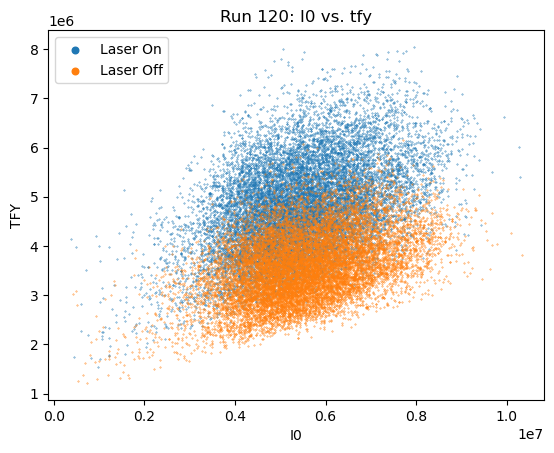

In [101]:
plt.figure()
plt.scatter(I0_int[laser_on], tfy_int[laser_on], s=0.1)
plt.scatter(I0_int[laser_off], tfy_int[laser_off], s=0.1)
plt.title(f'Run {run}: I0 vs. tfy')
plt.legend(['Laser On', 'Laser Off'], markerscale = 15)
plt.xlabel('I0')
plt.ylabel('TFY')
plt.show()

### TFY vs. SVLS
- This should have a linear fit as both are happening after the sample

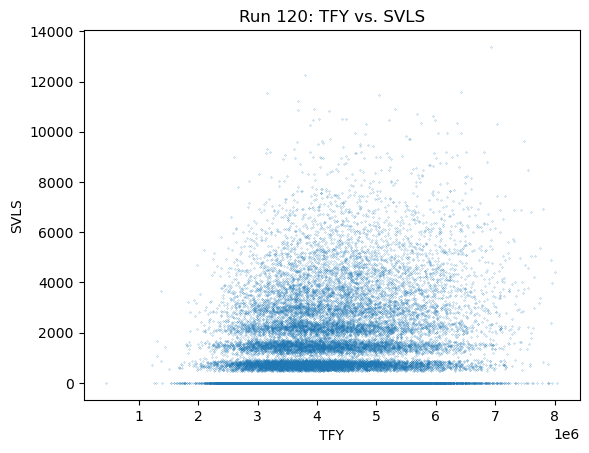

In [11]:
plt.figure()
plt.scatter(tfy_int, svls_int, s=0.03)
plt.title(f'Run {run}: TFY vs. SVLS')
plt.xlabel('TFY')
plt.ylabel('SVLS')
plt.show()

### I0 vs. Transmission (fzp piranha)


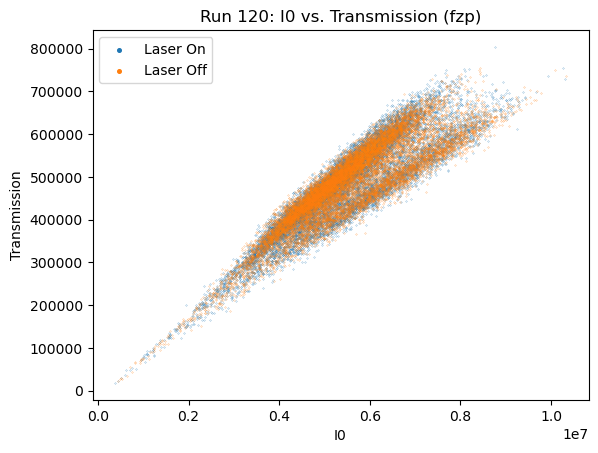

In [58]:
plt.figure()
plt.scatter(I0_int[laser_on], fzp_proj[laser_on], s=0.03, label='Laser On')
plt.scatter(I0_int[laser_off], fzp_proj[laser_off], s=0.03, label='Laser Off')
plt.title(f'Run {run}: I0 vs. Transmission (fzp)')
plt.xlabel('I0')
plt.ylabel('Transmission')
plt.legend(markerscale = 15)
plt.show()

# Plot out all of the different mono energy bins
- so 36 plots

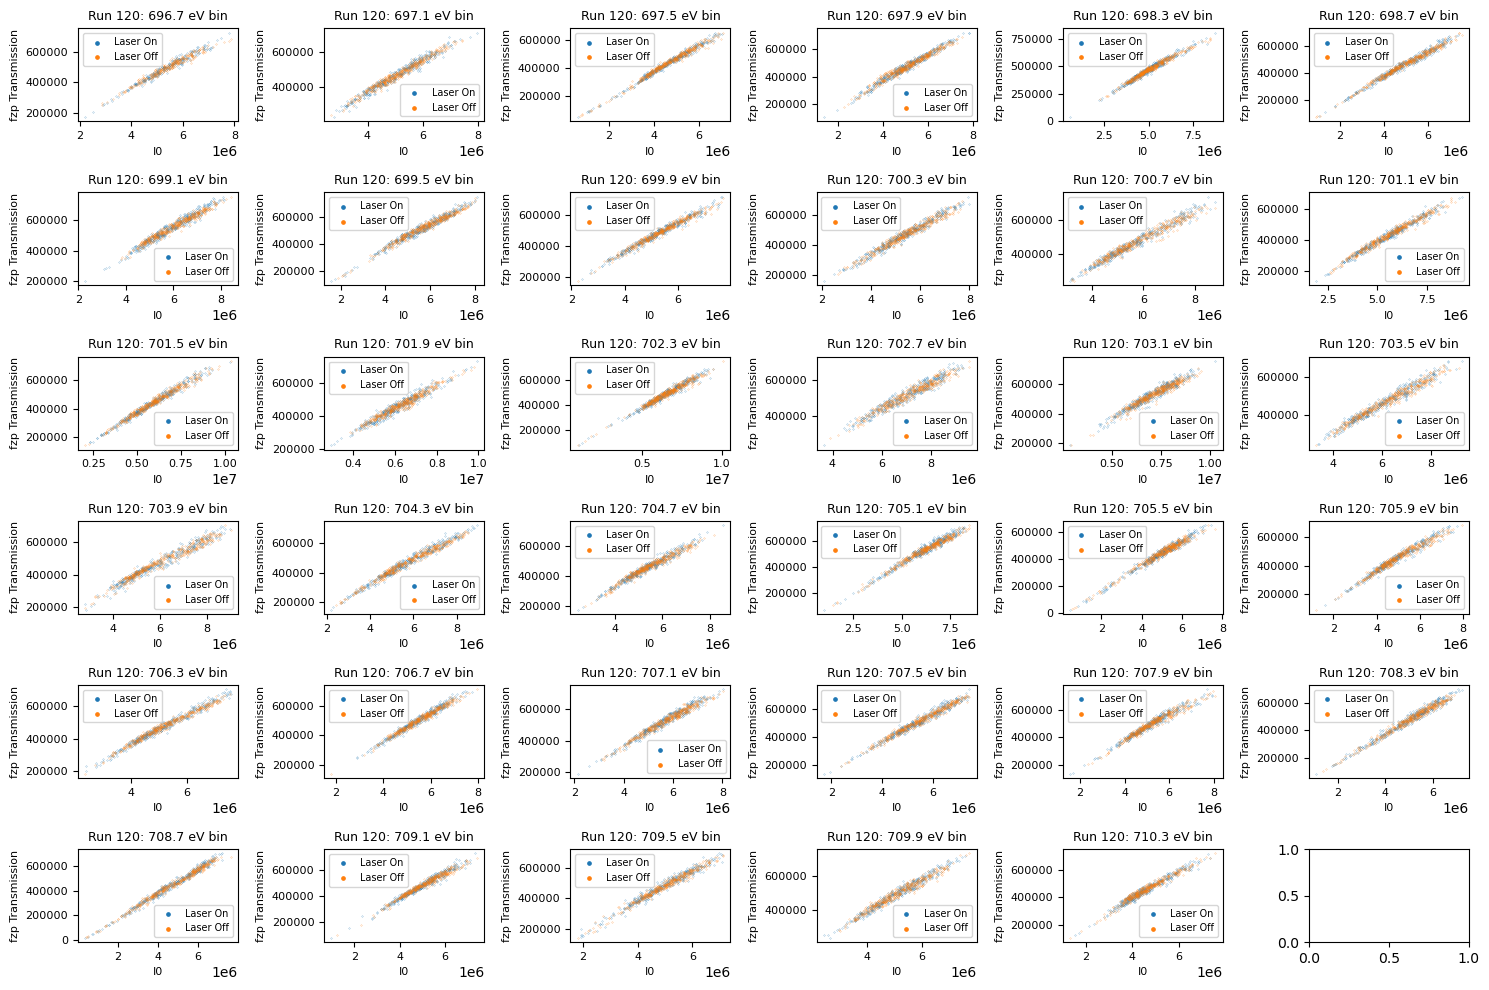

In [102]:
# 1. Define grid size (5 rows * 6 columns = 30 subplots)
rows = 6
cols = 6

# 2. Create the figure and a 2D array of axes
# Adjust figsize so the 30 plots are not squished
fig, axes = plt.subplots(rows, cols, figsize=(15, 10))

# 3. Flatten the 2D array into a 1D array for easier looping
axes_flat = axes.flatten()

# 4. Loop through each subplot and plot data
for i in range(num_bins):
    ax = axes_flat[i]
    
    mask_bins_on = (bin_idx == i) & laser_on
    mask_bins_off = (bin_idx == i) & laser_off
    
    x_on = I0_int[mask_bins_on]
    y_on = fzp_proj[mask_bins_on]
    x_off = I0_int[mask_bins_off]
    y_off = fzp_proj[mask_bins_off]
    
    # Plot on the specific axis
    ax.scatter(x_on, y_on, s = 0.025)
    ax.scatter(x_off, y_off, s = 0.025)
    ax.set_xlabel('I0', fontsize=8)
    ax.set_ylabel('fzp Transmission', fontsize=8)
    ax.set_title(f"Run 120: {bin_centers[i]:.1f} eV bin", fontsize=9)
    ax.legend(['Laser On', 'Laser Off'], markerscale = 15, fontsize=7)
    ax.tick_params(labelsize=8)

# 5. Automatically adjust spacing to prevent overlapping titles/labels
plt.tight_layout()
plt.show()

### I0 vs. TFY for all mono bins

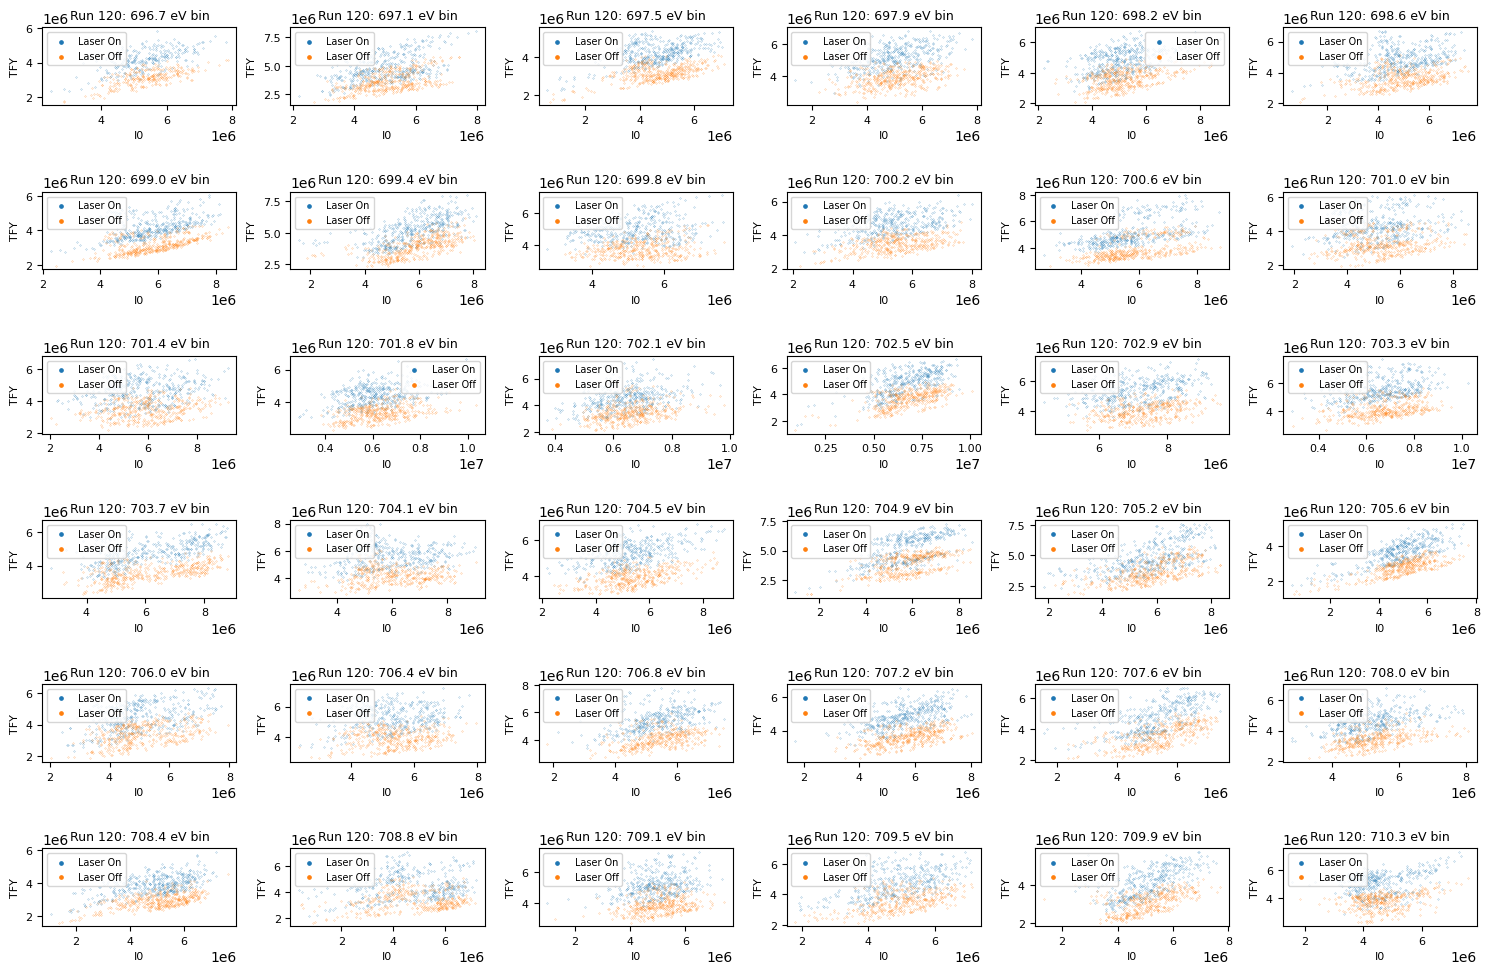

In [14]:
# 1. Define grid size (5 rows * 6 columns = 30 subplots)
rows = 6
cols = 6

# 2. Create the figure and a 2D array of axes
# Adjust figsize so the 30 plots are not squished
fig, axes = plt.subplots(rows, cols, figsize=(15, 10))

# 3. Flatten the 2D array into a 1D array for easier looping
axes_flat = axes.flatten()

# 4. Loop through each subplot and plot data
for i in range(num_bins):
    ax = axes_flat[i]
    
    mask_bins_on = (bin_idx == i) & laser_on
    mask_bins_off = (bin_idx == i) & laser_off
    
    x_on = I0_int[mask_bins_on]
    y_on = tfy_int[mask_bins_on]
    x_off = I0_int[mask_bins_off]
    y_off = tfy_int[mask_bins_off]
    
    # Plot on the specific axis
    ax.scatter(x_on, y_on, s = 0.025)
    ax.scatter(x_off, y_off, s = 0.025)
    ax.set_xlabel('I0', fontsize=8)
    ax.set_ylabel('TFY', fontsize=8)
    ax.legend(['Laser On', 'Laser Off'], markerscale = 15, fontsize=7)
    ax.set_title(f"Run 120: {bin_centers[i]:.1f} eV bin", fontsize=9)
    ax.tick_params(labelsize=8)

# 5. Automatically adjust spacing to prevent overlapping titles/labels
plt.tight_layout()
plt.show()

### Find the best linear fit and conduct the filter to remove bad shots

Text(0, 0.5, 'Transmission')

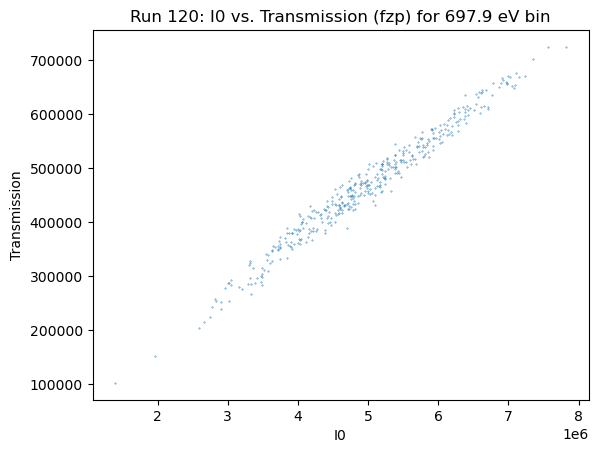

In [15]:
# test with just one of the energy bins
mask_bins_on_3 = (bin_idx == 3) & laser_on
mask_bins_off_3 = (bin_idx == 3) & laser_off
i0_test = I0_int[mask_bins_on_3]
fzp_test = fzp_proj[mask_bins_on_3]
plt.figure()
plt.scatter(i0_test, fzp_test, s=0.1)
plt.title(f'Run {run}: I0 vs. Transmission (fzp) for {bin_centers[3]:.1f} eV bin')
plt.xlabel('I0')
plt.ylabel('Transmission')

Slope: 0.09665408013124505, Intercept: -13862.705281317816, R-squared: 0.9733640703895756


Text(0, 0.5, 'Transmission')

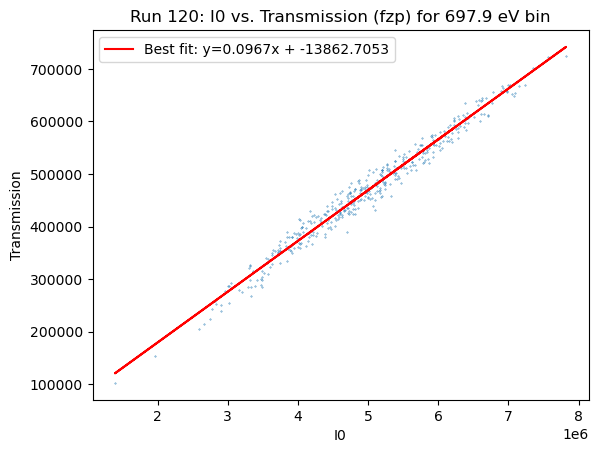

In [16]:
# start with initial function to determine the line of best fit
slope, intercept, r_value, p_value, std_err = st.linregress(i0_test, fzp_test)
print(f"Slope: {slope}, Intercept: {intercept}, R-squared: {r_value**2}")
plt.figure()
plt.scatter(i0_test, fzp_test, s=0.1)
plt.plot(i0_test, slope*i0_test + intercept, color='red', label=f'Best fit: y={slope:.4f}x + {intercept:.4f}')
plt.title(f'Run {run}: I0 vs. Transmission (fzp) for {bin_centers[3]:.1f} eV bin')
plt.xlabel('I0')
plt.legend()
plt.ylabel('Transmission')

#### actual function for doign the correlation filter and removing bad shots

In [5]:
import numpy as np
from scipy.stats import linregress


def filter_correlation(x, y, selection_mask=None,
                       trim_method='tukey', trim_k=1.5, trim_axes='both', trim_pct=0.5,
                       n_bins=20, sigma_thresh=3.0, min_pts_per_bin=20,
                       n_iter=10, verbose=True):
    """
    Filter shots that don't follow the linear I0/transmission correlation.

    Stage 1 — trim marginal extremes in value space (before any fit), so sparse
              high-leverage points at the ends can't tilt the line toward themselves.
    Stage 2 — fit a line to survivors, then clip by per-bin residual spread (MAD),
              iterating so the fit isn't dragged by points about to be removed.

    Parameters
    ----------
    x, y : full-length arrays (e.g. I0 and transmission, one entry per shot)
    selection_mask : full-length bool mask of shots to consider (mono & laser & ...).
                     None = use every shot.
    trim_method : 'tukey' (Q1-k*IQR .. Q3+k*IQR), 'percentile', or 'mad'
    trim_k : Tukey/MAD multiplier. 1.5 = standard, 3.0 = conservative.
    trim_axes : 'x', 'y', or 'both'
    n_bins : equal-count bins along x for local residual spread
    sigma_thresh : clip beyond this many MAD-sigmas of the bin's residuals
    min_pts_per_bin : bins smaller than this are kept wholesale (spread untrustworthy)
    n_iter : max fit/clip iterations; exits early once the mask stops changing

    Returns
    -------
    final_mask : full-length bool array, True = shot passed every stage
    fit        : scipy linregress result from the final iteration
    keep       : bool array over the *selected* subset (aligns with selected_idx)
    info       : dict of bounds and per-stage counts
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    if selection_mask is None:
        selection_mask = np.ones(x.size, dtype=bool)
    selected_idx = np.flatnonzero(selection_mask)
    x_sel, y_sel = x[selection_mask], y[selection_mask]
    n_start = x_sel.size
    if n_start == 0:
        raise ValueError("selection_mask selects no shots")

    # ------------------------------------------------------------------
    # Stage 1: marginal (value-space) trimming — BEFORE the fit
    # ------------------------------------------------------------------
    axis_names = {'x': 'x', 'y': 'y', 'both': 'xy'}[trim_axes]
    V = np.asarray({'x': [x_sel], 'y': [y_sel], 'both': [x_sel, y_sel]}[trim_axes])

    if trim_method == 'tukey':
        q1, q3 = np.percentile(V, [25, 75], axis=1)
        iqr = q3 - q1
        lo, hi = q1 - trim_k * iqr, q3 + trim_k * iqr
    elif trim_method == 'percentile':
        lo, hi = np.percentile(V, [trim_pct, 100 - trim_pct], axis=1)
    elif trim_method == 'mad':
        med = np.median(V, axis=1, keepdims=True)
        spread = 1.4826 * np.median(np.abs(V - med), axis=1)
        med = med.ravel()
        lo, hi = med - trim_k * spread, med + trim_k * spread
    else:
        raise ValueError(f"unknown trim_method: {trim_method}")

    keep = np.all((V >= lo[:, None]) & (V <= hi[:, None]), axis=0)
    n_after_trim = int(keep.sum())
    if n_after_trim < 2:
        raise ValueError("trimming removed nearly everything — loosen trim_k")

    # ------------------------------------------------------------------
    # Stage 2: fit + per-bin residual clipping
    # ------------------------------------------------------------------
    order = np.argsort(x_sel, kind='stable')      # x_sel never changes — sort once
    fit = None

    for _ in range(n_iter):
        fit = linregress(x_sel[keep], y_sel[keep])
        resid = y_sel - (fit.slope * x_sel + fit.intercept)

        alive = order[keep[order]]                # surviving points, sorted by x
        n_alive = alive.size

        # equal-count bins packed into a NaN-padded grid for vectorized stats
        edges = np.linspace(0, n_alive, n_bins + 1).astype(int)
        counts = np.diff(edges)
        counts = counts[counts > 0]
        n_b = counts.size

        maxc = counts.max()
        valid = np.arange(maxc)[None, :] < counts[:, None]
        grid = np.full((n_b, maxc), np.nan)
        grid[valid] = resid[alive]

        center = np.nanmedian(grid, axis=1, keepdims=True)
        spread = 1.4826 * np.nanmedian(np.abs(grid - center), axis=1, keepdims=True)

        ok = np.abs(grid - center) < sigma_thresh * spread
        degenerate = ((counts < min_pts_per_bin)
                      | ~np.isfinite(spread[:, 0])
                      | (spread[:, 0] == 0))
        ok[degenerate] = True                     # too sparse to judge — keep them

        new_keep = np.zeros(n_start, dtype=bool)
        new_keep[alive[ok[valid]]] = True         # trimmed points never resurrect

        if np.array_equal(new_keep, keep):
            break
        keep = new_keep

    n_final = int(keep.sum())
    info = {
        'bounds': {ax: (float(l), float(h)) for ax, l, h in zip(axis_names, lo, hi)},
        'n_selected': n_start,
        'n_after_trim': n_after_trim,
        'n_final': n_final,
        'n_trimmed': n_start - n_after_trim,
        'n_clipped': n_after_trim - n_final,
    }

    if verbose:
        print(f"stage 1 (extremes) : {info['n_trimmed']:>6d} removed "
              f"({100*info['n_trimmed']/n_start:.2f}%)")
        for ax, (l, h) in info['bounds'].items():
            print(f"   {ax} kept range : [{l:.1f}, {h:.1f}]")
        print(f"stage 2 (residuals): {info['n_clipped']:>6d} removed "
              f"({100*info['n_clipped']/max(n_after_trim,1):.2f}%)")
        print(f"final              : {n_final} / {n_start} kept "
              f"({100*n_final/n_start:.1f}%)")
        print(f"slope={fit.slope:.4f}  intercept={fit.intercept:.1f}  "
              f"r²={fit.rvalue**2:.4f}  slope_err={fit.stderr:.4g}")

    final_mask = np.zeros(x.size, dtype=bool)
    final_mask[selected_idx[keep]] = True
    return final_mask, fit, keep, info

stage 1 (extremes) :      3 removed (0.73%)
   x kept range : [2049338.4, 7937139.8]
   y kept range : [211380.6, 732537.3]
stage 2 (residuals):      0 removed (0.00%)
final              : 407 / 410 kept (99.3%)
slope=0.0962  intercept=-11174.8  r²=0.9719  slope_err=0.0008131


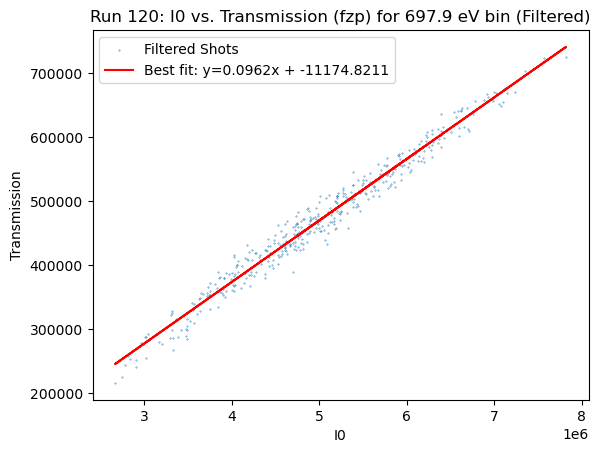

{'bounds': {'x': (2049338.4386363747, 7937139.838636343), 'y': (211380.59944444455, 732537.2527777776)}, 'n_selected': 410, 'n_after_trim': 407, 'n_final': 407, 'n_trimmed': 3, 'n_clipped': 0}
[False False False ... False False False]


In [80]:
final_mask, fit, keep, info= filter_correlation(I0_int, fzp_proj, mask_bins_on_3)


plt.figure()
plt.scatter(i0_test[keep], fzp_test[keep], s=0.1, label='Filtered Shots')
plt.plot(i0_test[keep], fit.slope*i0_test[keep] + fit.intercept, color='red', label=f'Best fit: y={fit.slope:.4f}x + {fit.intercept:.4f}')
plt.title(f'Run {run}: I0 vs. Transmission (fzp) for {bin_centers[3]:.1f} eV bin (Filtered)')
plt.xlabel('I0')
plt.ylabel('Transmission')
plt.legend()  
plt.show()

print(info)
print(final_mask)

### Now apply this correlation filter to all the energy bins within this run

#### before filtering

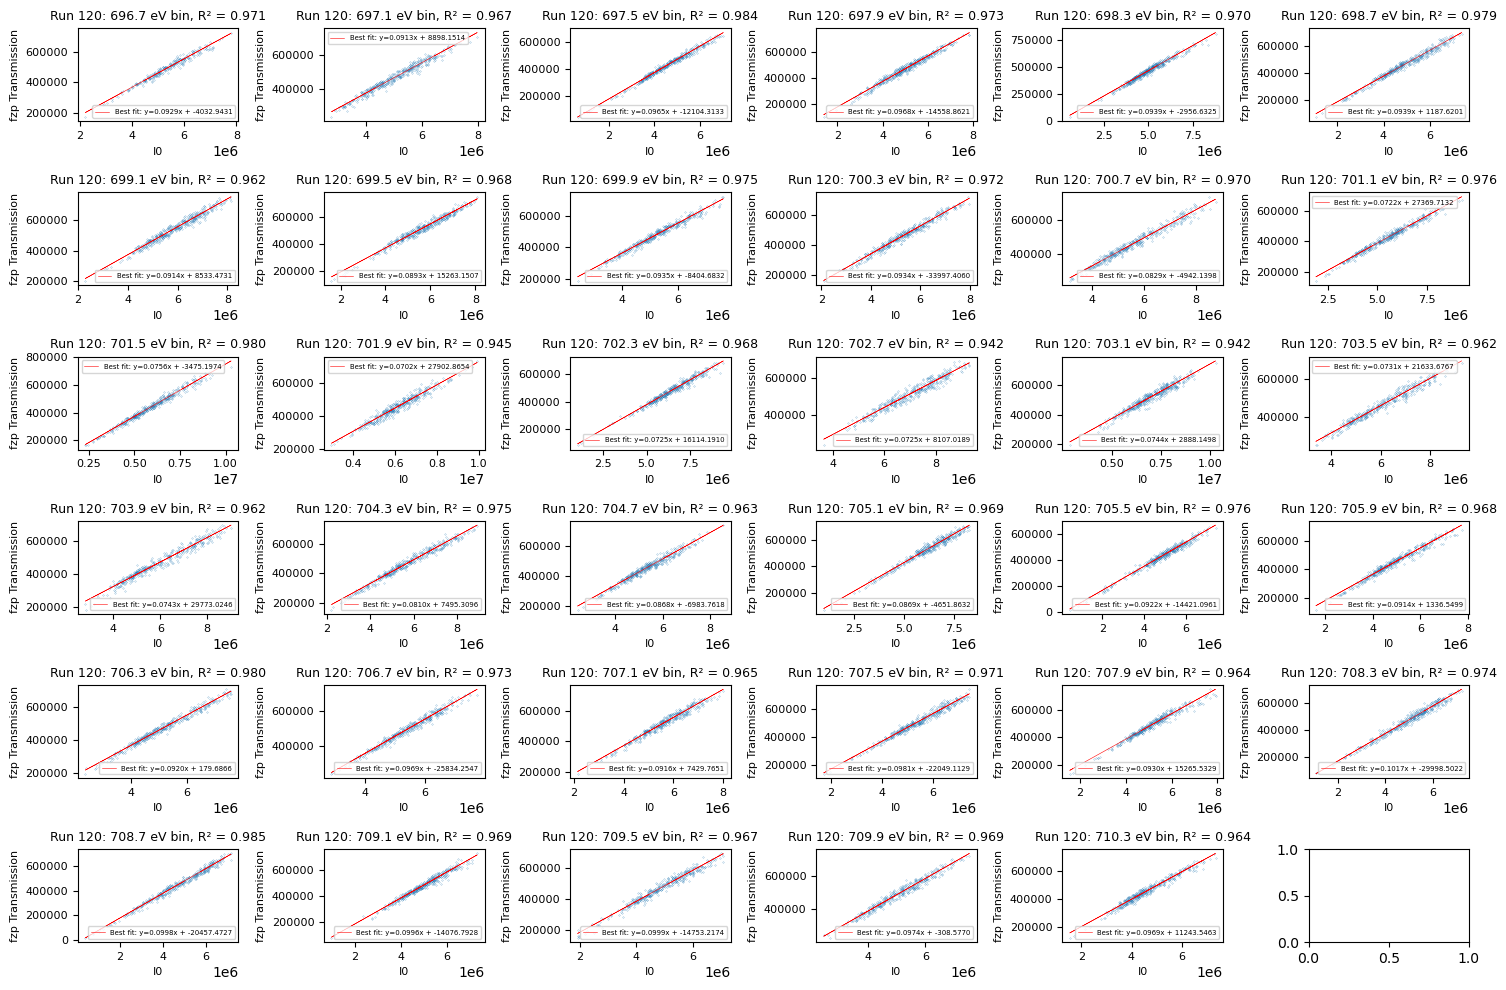

In [62]:
# 1. Define grid size (5 rows * 6 columns = 30 subplots)
rows = 6
cols = 6

# 2. Create the figure and a 2D array of axes
# Adjust figsize so the 30 plots are not squished
fig, axes = plt.subplots(rows, cols, figsize=(15, 10))

# 3. Flatten the 2D array into a 1D array for easier looping
axes_flat = axes.flatten()

# 4. Loop through each subplot and plot data
for i in range(num_bins):
    ax = axes_flat[i]
    
    mask_bins_on = (bin_idx == i) & laser_on
    mask_bins_off = (bin_idx == i) & laser_off
    
    x_on = I0_int[mask_bins_on]
    y_on = fzp_proj[mask_bins_on]
    
    slope, intercept, r_value, p_value, std_err = st.linregress(x_on, y_on)
    
    # Plot on the specific axis
    ax.scatter(x_on, y_on, s = 0.025)
    ax.plot(x_on, slope*x_on + intercept, color='red', label=f'Best fit: y={slope:.4f}x + {intercept:.4f}', linewidth=0.4)
    ax.set_xlabel('I0', fontsize=8)
    ax.set_ylabel('fzp Transmission', fontsize=8)
    ax.set_title(f"Run 120: {bin_centers[i]:.1f} eV bin, R² = {r_value**2:.3f}", fontsize=9)
    ax.legend(markerscale = 2, fontsize=5)
    ax.tick_params(labelsize=8)

# 5. Automatically adjust spacing to prevent overlapping titles/labels
plt.tight_layout()
plt.show()

#### After Correlation Filter

stage 1 (extremes) :      4 removed (1.54%)
   x kept range : [3154094.0, 7587135.9]
   y kept range : [276258.2, 713603.4]
stage 2 (residuals):      0 removed (0.00%)
final              : 256 / 260 kept (98.5%)
slope=0.0916  intercept=3328.3  r²=0.9628  slope_err=0.00113
stage 1 (extremes) :      1 removed (0.24%)
   x kept range : [1980399.9, 8109375.3]
   y kept range : [206041.3, 738470.8]
stage 2 (residuals):     20 removed (4.90%)
final              : 388 / 409 kept (94.9%)
slope=0.0901  intercept=13928.5  r²=0.9717  slope_err=0.0007827
stage 1 (extremes) :     10 removed (2.44%)
   x kept range : [1756589.2, 7455431.3]
   y kept range : [170400.5, 695983.3]
stage 2 (residuals):     11 removed (2.76%)
final              : 388 / 409 kept (94.9%)
slope=0.0974  intercept=-15686.1  r²=0.9824  slope_err=0.0006629
stage 1 (extremes) :      3 removed (0.73%)
   x kept range : [2049338.4, 7937139.8]
   y kept range : [211380.6, 732537.3]
stage 2 (residuals):      0 removed (0.00%)
final 

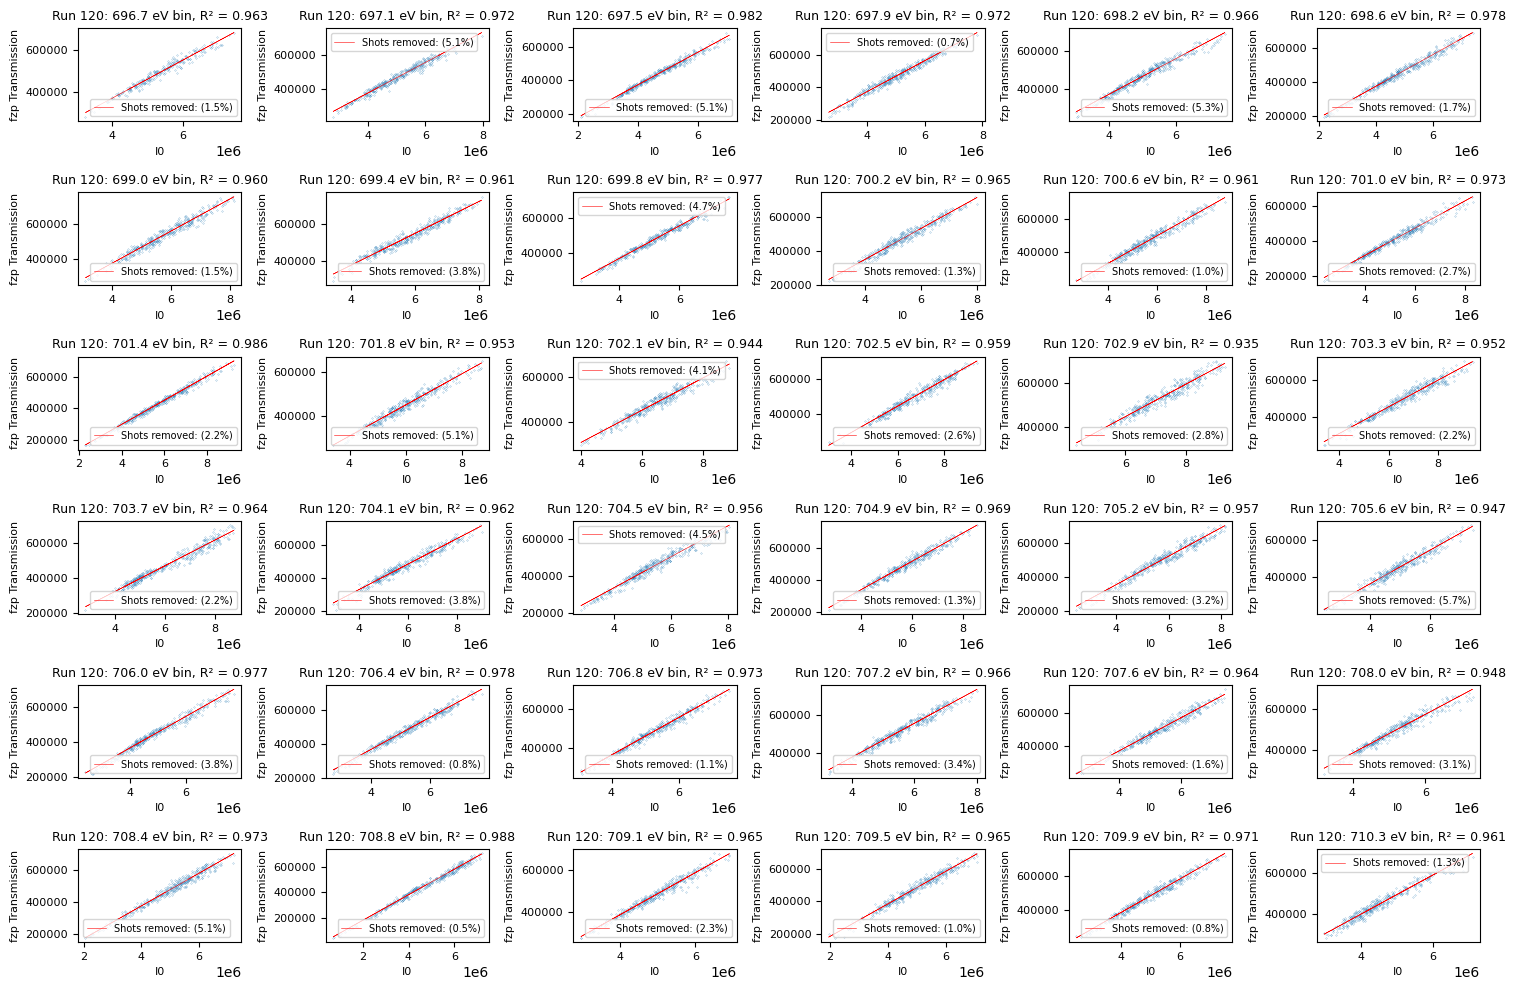

13879


In [20]:
# 1. Define grid size (5 rows * 6 columns = 30 subplots)
rows = 6
cols = 6

# 2. Create the figure and a 2D array of axes
# Adjust figsize so the 30 plots are not squished
fig, axes = plt.subplots(rows, cols, figsize=(15, 10))

# 3. Flatten the 2D array into a 1D array for easier looping
axes_flat = axes.flatten()

# overall mask for the entire run
final_final_mask = np.zeros(len(I0_int), dtype=bool)

# 4. Loop through each subplot and plot data
for i in range(num_bins):
    ax = axes_flat[i]
    
    mask_bins_on = (bin_idx == i) & laser_on
    mask_bins_off = (bin_idx == i) & laser_off
    
    x_on = I0_int[mask_bins_on]
    y_on = fzp_proj[mask_bins_on]
    
    final_mask, fit, keep, info= filter_correlation(I0_int, fzp_proj, mask_bins_on)
    
    final_final_mask |= final_mask  # accumulate the overall mask for the entire run
    
    x_keep = I0_int[final_mask]
    y_keep = fzp_proj[final_mask]
        
    # percent shots removed
    percent_removed = (info['n_selected'] - info['n_final']) / info['n_selected'] * 100
    # Plot on the specific axis
    ax.scatter(x_keep, y_keep, s = 0.025)
    ax.plot(x_keep, fit.slope*x_keep + fit.intercept, color='red', label=f'Shots removed: ({percent_removed:.1f}%)', linewidth=0.4)
    ax.set_xlabel('I0', fontsize=8)
    ax.set_ylabel('fzp Transmission', fontsize=8)
    ax.set_title(f"Run 120: {bin_centers[i]:.1f} eV bin, R² = {fit.rvalue**2:.3f}", fontsize=9)
    ax.legend(markerscale = 0.1, fontsize=7)
    ax.tick_params(labelsize=8)

# 5. Automatically adjust spacing to prevent overlapping titles/labels
plt.tight_layout()
plt.show()


print(final_final_mask.sum())

### See if there are any differences before and after filtering in the PFY
- final_mask_on: the mask for all of the laser on good shots that made it through
- final_mask_off: the mask for all of the laser off good shots that made it through

With these masks, then I can plot out the PFY which, would just the the SLVS normalized by I0 per shot and plotted agaisnt mono
The difference signal would then be Laser on - Laser off

In [11]:
final_mask_on = np.zeros(len(I0_int), dtype=bool)
final_mask_off = np.zeros(len(I0_int), dtype=bool)

# loop through all the bins to calculate the final mask for laser on and laser off shots
binned_svls_on = np.zeros(num_bins)
binned_svls_off = np.zeros(num_bins)

orig_binned_svls_on = np.zeros(num_bins)
orig_binned_svls_off = np.zeros(num_bins)

# normalize by I0
I0_on = I0_int[laser_on]
I0_off = I0_int[laser_off]
svls_norm = svls_int / I0_int

for i in range(num_bins):
    mask_bins_on = (bin_idx == i) & laser_on
    mask_bins_off = (bin_idx == i) & laser_off

    
    
    filtered_mask_on, fit_on, keep_on, info_on= filter_correlation(I0_int, fzp_proj, mask_bins_on, verbose=False, sigma_thresh=1.5)
    filtered_mask_off, fit_off, keep_off, info_off = filter_correlation(I0_int, fzp_proj, mask_bins_off, verbose=False, sigma_thresh=1.5)
    
    # with shots removed
    binned_svls_on[i] = np.nanmean(svls_norm[filtered_mask_on])
    
    binned_svls_off[i] = np.nanmean(svls_norm[filtered_mask_off])
    
    # without shots removed
    orig_binned_svls_on[i] = np.nanmean(svls_norm[mask_bins_on])
    orig_binned_svls_off[i] = np.nanmean(svls_norm[mask_bins_off])



print(binned_svls_on)
print(binned_svls_off)


fig, ax = plt.subplots(1, 2, figsize=(10, 6))
ax[0].plot(bin_centers, binned_svls_on, markersize=0.5, label='Laser On')
ax[0].plot(bin_centers, binned_svls_off, markersize=0.5, label='Laser Off')
ax[0].set_title(f'Run {run}: Normalized PFY')
ax[0].set_xlabel('Mono Energy (eV)')
ax[0].set_ylabel('Normalized SVLS (SVLS/I0)')
ax[0].legend()

ax[1].plot(bin_centers, binned_svls_on - binned_svls_off, markersize=0.5, label='difference')
ax[1].set_title(f'Run {run}: Normalized Difference PFY (Laser On - Laser Off)')
ax[1].set_xlabel('Mono Energy (eV)')
ax[1].set_ylabel('Normalized SVLS (SVLS/I0)')
plt.legend()
plt.show()


# plot out the normal spectrum before removing any shots
fig1, ax1 = plt.subplots(1, 2, figsize=(10, 6))
ax1[0].plot(bin_centers, orig_binned_svls_on, markersize=0.5, label='Laser On')
ax1[0].plot(bin_centers, orig_binned_svls_off, markersize=0.5, label='Laser Off')
ax1[0].set_title(f'Run {run}: Normalized PFY')
ax1[0].set_xlabel('Mono Energy (eV)')
ax1[0].set_ylabel('Normalized SVLS (SVLS/I0)')

ax1[1].plot(bin_centers, orig_binned_svls_on - orig_binned_svls_off, markersize=0.5, label='difference')
ax1[1].set_title(f'Run {run}: Normalized Difference PFY (Laser On - Laser Off)')
ax1[1].set_xlabel('Mono Energy (eV)')
ax1[1].set_ylabel('Normalized SVLS (SVLS/I0)')
plt.legend()
plt.show()

# bin the integrated shots together
bin_idx, bin_centers = bin_mono_energy(mono, num_bins, (696.5, 710.5))


NameError: name 'laser_on' is not defined

### Reduce for 1 run

In [ ]:
def reduce(run_num, bg_run_num, sigma_tresh, num_bins):
    """
    
    """
    
    t0 = time.time()
    
    
    # 1. Load the raw Data
    
    base = '/sdf/data/lcls/ds/rix/'
    exp  = 'rix101231825'
    fname = f'{base}/{exp}/hdf5/smalldata/{exp}_Run{run_num:04d}.h5' 
    bg_86_path = f'/sdf/home/j/jwang343/rix101231825_Fe_L_edge/results/Jeff/DataAcceleratorChemRIXS/jupyter_notebook/proc/BG_run{bg_run_num}.h5'
    t_load = time.time()
    # process the background svls
    with h5py.File(bg_86_path, 'r') as h5:  
        bg_proc  = h5['axis_svls'][:]
    
    with h5py.File(fname, 'r') as h5:
        g       = h5['intg/axis_svls']
        count   = g['count'][:].squeeze()
        event_codes = g['timing_sum_eventcodes'][:]
        monoenc = g['mono_hrencoder_sum_value'][:].squeeze()
        fim0_wf = g['det_rix_fim0_sum_full_area'][:]
        fim1_wf = g['det_rix_fim1_sum_full_area'][:]
        svls_proj = g['droplet_dense_curve_corr_pj_ax_1_data'][:]
        fzp = g['fzp_piranha_sum_full_area'][:]
        epics = h5['epics_archiver']
        
    print(f"  h5 read: {time.time()-t_load:.1f}s")
    
    t_proc = time.time()
        
    # yaml file
    fyaml = '../roi_input.yml'  
    with open(fyaml) as f:
        cfg = yaml.safe_load(f)
    fim0_cfg = cfg['fim0']
    fim1_cfg = cfg['fim1']
    fzp_cfg = cfg['fzp']
    evc_cfg = cfg['evc']
    mono_cfg = cfg['mono_calib']

    ## SVLS processing yaml values
    thresh_min = cfg['svls']['threshold'][0]
    thresh_max = cfg['svls']['threshold'][1]

    # mono energy array
    mono = get_mono(monoenc, mono_cfg, run_num, count)
    
    
    # 2. First level of processing detectors to get per frame values
    
    # SVLS 
    svls_proj[svls_proj <thresh_min] = 0
    svls_proj[svls_proj >thresh_max] = 0
    svls_proj[np.isnan(svls_proj)] = 0

    svls_proj = svls_proj-bg_proc
    
    svls_int = svls_proj.sum(axis = 1)
    svls_int = svls_int.flatten()
    
    # I0 (fims)
    I0_int = i0_sum(fim0_wf, fim0_cfg) + i0_sum(fim1_wf, fim1_cfg)
    I0_int = I0_int.flatten()
    
    
    # fzp
    bg_0 = fzp[:,fzp_cfg['offset_roi'][0]:fzp_cfg['offset_roi'][1]].mean(axis = 1) # Example: background region for left part
    fzp_0_bgsub = fzp - bg_0[:, np.newaxis]
    # take the roi region and sum over the pixels to get an intensity value per frame
    fzp_proj = fzp_0_bgsub[:,fzp_cfg['roi'][0]:fzp_cfg['roi'][1]].sum(axis = 1)
    fzp_proj = fzp_proj.flatten() 
    

    # 3. create masks
    
    # laser on / laser off 
    expected_count = st.mode(count, keepdims=False)[0]
    laser_on  = np.asarray(event_codes[:, evc_cfg[True]]  / expected_count > 0.5).squeeze()
    laser_off = np.asarray(event_codes[:, evc_cfg[False]] / expected_count > 0.5).squeeze()
    
    # mono bins
    bin_idx, bin_centers = bin_mono_energy(mono, num_bins, (696.5, 710.5))
    
    
    # 4. 5. 6.
    
    # loop through all the bins to calculate the final mask for laser on and laser off shots
    PFY_on_mean_filtered = np.zeros(num_bins)
    PFY_off_mean_filtered = np.zeros(num_bins)

    PFY_on_mean = np.zeros(num_bins)
    PFY_off_mean = np.zeros(num_bins)
    
    counts_on_filtered = np.zeros(num_bins)
    counts_off_filtered = np.zeros(num_bins)
    
    counts_on = np.zeros(num_bins)
    counts_off = np.zeros(num_bins)


    # normalize by I0
    svls_norm = svls_int / I0_int

    for i in range(num_bins):
        mask_bins_on = (bin_idx == i) & laser_on
        mask_bins_off = (bin_idx == i) & laser_off

        
        
        filtered_mask_on, fit_on, keep_on, info_on= filter_correlation(I0_int, fzp_proj, mask_bins_on, verbose=False, sigma_thresh=sigma_tresh)
        filtered_mask_off, fit_off, keep_off, info_off = filter_correlation(I0_int, fzp_proj, mask_bins_off, verbose=False, sigma_thresh=sigma_tresh)
        
        # with shots removed
        PFY_on_mean_filtered[i] = np.nanmean(svls_norm[filtered_mask_on])
        counts_on_filtered[i] = np.sum(filtered_mask_on)
        PFY_off_mean_filtered[i] = np.nanmean(svls_norm[filtered_mask_off])
        counts_off_filtered[i] = np.sum(filtered_mask_off)
        
        # without shots removed
        PFY_on_mean[i] = np.nanmean(svls_norm[mask_bins_on])
        counts_on[i] = np.sum(mask_bins_on)
        PFY_off_mean[i] = np.nanmean(svls_norm[mask_bins_off])
        counts_off[i] = np.sum(mask_bins_off)
        
    scanvar = bin_centers

    
    # clear up big variables before the next load
    del fim0_wf, fim1_wf, fzp, svls_proj, fzp_0_bgsub
    gc.collect()  
    
    print(f"  processing: {time.time()-t_proc:.1f}s")
    
    t1 = time.time()
    print(f"run {run_num}: {t1-t0:.1f}s, "
      f"peak RSS {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss/1e6:.1f} GB")
    t0 = time.time()
    
    return counts_on, counts_on_filtered, counts_off, counts_off_filtered, PFY_on_mean, PFY_on_mean_filtered, PFY_off_mean, PFY_off_mean_filtered, scanvar

In [39]:
def reduce(run_num, bg_run_num, sigma_tresh, num_bins,
           despeckle=True, kernel_size=3, n_sigma=10):
    """
    Perform data reduction for a given run and background run, applying a sigma threshold and binning the data into the specified number of bins.
        
        Steps to reduction: 
        1. Load the raw data for the specified run and background run
            - raw SVLS
            - raw I0 (fims)
            - raw transmission (fzp)
        2. first level process of the detectors to get per frame values shape: (frames, value)
            - apply background subtraction to raw SLVS
            - sum over good fim channels to get I0 
            - sum over fzp ROI to get transmission per frame
        3. create masks 
            - laser on/off mask per frame
            - mono bin mask
        4. correlation filter good and bad shots based on the sigma threshold, creates new mask for filtered shots
        
        actual processing steps: 
        5. normalize PFY with I0 for all frames
        6. average the normlized laser on and laser off frames per bin for both filtered and not filtered
        7. return everything
        
        
        keys:
        counts_on (num_bins,) the counts within each bin for laser on
        counts_on_filtered (num_bins,) the counts within each bin for laser on after filtering
        counts_off (num_bins,) the counts within each bin for laser off
        counts_off_filtered (num_bins,) the counts within each bin for laser off after filtering
        PFY_on_mean (num_bins,) the mean PFY for laser on frames per bin
        PFY_on_mean_filtered (num_bins,) the mean PFY for laser on frames per bin after filtering
        PFY_off_mean (num_bins,) the mean PFY for laser off frames per bin
        PFY_off_mean_filtered (num_bins,) the mean PFY for laser off frames per bin after filtering
    """
    t0 = time.time()

    # ------------------------------------------------------------------
    # 1. Load raw data
    # ------------------------------------------------------------------
    base = '/sdf/data/lcls/ds/rix/'
    exp  = 'rix101231825'
    fname = f'{base}/{exp}/hdf5/smalldata/{exp}_Run{run_num:04d}.h5'
    bg_86_path = (f'/sdf/home/j/jwang343/rix101231825_Fe_L_edge/results/Jeff/'
                  f'DataAcceleratorChemRIXS/jupyter_notebook/proc/BG_run{bg_run_num}.h5')

    t_load = time.time()
    with h5py.File(bg_86_path, 'r') as h5:
        bg_proc = h5['axis_svls'][:]

    with h5py.File(fname, 'r') as h5:
        g           = h5['intg/axis_svls']
        count       = g['count'][:].squeeze()
        event_codes = g['timing_sum_eventcodes'][:]
        monoenc     = g['mono_hrencoder_sum_value'][:].squeeze()
        fim0_wf     = g['det_rix_fim0_sum_full_area'][:]
        fim1_wf     = g['det_rix_fim1_sum_full_area'][:]
        svls_proj   = g['droplet_dense_curve_corr_pj_ax_1_data'][:]
        fzp         = g['fzp_piranha_sum_full_area'][:]
    print(f"  h5 read: {time.time()-t_load:.1f}s")

    t_proc = time.time()

    # yaml config
    fyaml = '../roi_input.yml'
    with open(fyaml) as f:
        cfg = yaml.safe_load(f)
    fim0_cfg, fim1_cfg = cfg['fim0'], cfg['fim1']
    fzp_cfg, evc_cfg   = cfg['fzp'], cfg['evc']
    mono_cfg           = cfg['mono_calib']
    thresh_min, thresh_max = cfg['svls']['threshold']

    mono = get_mono(monoenc, mono_cfg, run_num, count)

    # ------------------------------------------------------------------
    # 2. Per-frame detector processing
    # ------------------------------------------------------------------
    # SVLS -- keep the 2-D (frames, pixels) shape this time
    svls_proj[svls_proj < thresh_min] = 0
    svls_proj[svls_proj > thresh_max] = 0
    svls_proj[np.isnan(svls_proj)]    = 0
    svls_proj = svls_proj - bg_proc

    n_pix = svls_proj.shape[1]

    # I0
    I0_int = (i0_sum(fim0_wf, fim0_cfg) + i0_sum(fim1_wf, fim1_cfg)).flatten()

    # FZP transmission
    bg_0        = fzp[:, fzp_cfg['offset_roi'][0]:fzp_cfg['offset_roi'][1]].mean(axis=1)
    fzp_bgsub   = fzp - bg_0[:, np.newaxis]
    fzp_proj    = fzp_bgsub[:, fzp_cfg['roi'][0]:fzp_cfg['roi'][1]].sum(axis=1).flatten()

    # ------------------------------------------------------------------
    # 3. Masks
    # ------------------------------------------------------------------
    expected_count = st.mode(count, keepdims=False)[0]
    laser_on  = np.asarray(event_codes[:, evc_cfg[True]]  / expected_count > 0.5).squeeze()
    laser_off = np.asarray(event_codes[:, evc_cfg[False]] / expected_count > 0.5).squeeze()

    bin_idx, bin_centers = bin_mono_energy(mono, num_bins, (696.5, 710.5))

    # ------------------------------------------------------------------
    # 4-6. Filter, bin into 2-D maps
    # ------------------------------------------------------------------
    svls_norm_2d = svls_proj / I0_int[:, np.newaxis]      # (frames, pixels)

    map_on           = np.zeros((num_bins, n_pix))
    map_off          = np.zeros((num_bins, n_pix))
    map_on_filtered  = np.zeros((num_bins, n_pix))
    map_off_filtered = np.zeros((num_bins, n_pix))

    counts_on           = np.zeros(num_bins)
    counts_off          = np.zeros(num_bins)
    counts_on_filtered  = np.zeros(num_bins)
    counts_off_filtered = np.zeros(num_bins)

    for i in range(num_bins):
        mask_bins_on  = (bin_idx == i) & laser_on
        mask_bins_off = (bin_idx == i) & laser_off

        filtered_mask_on, *_  = filter_correlation(I0_int, fzp_proj, mask_bins_on,
                                                   verbose=False, sigma_thresh=sigma_tresh)
        filtered_mask_off, *_ = filter_correlation(I0_int, fzp_proj, mask_bins_off,
                                                   verbose=False, sigma_thresh=sigma_tresh)

        counts_on[i]           = mask_bins_on.sum()
        counts_off[i]          = mask_bins_off.sum()
        counts_on_filtered[i]  = filtered_mask_on.sum()
        counts_off_filtered[i] = filtered_mask_off.sum()

        # empty bins stay zero -- the count carries zero weight downstream,
        # and this avoids NaNs poisoning the multi-run weighted average
        if counts_on[i]:
            map_on[i] = np.nanmean(svls_norm_2d[mask_bins_on], axis=0)
        if counts_off[i]:
            map_off[i] = np.nanmean(svls_norm_2d[mask_bins_off], axis=0)
        if counts_on_filtered[i]:
            map_on_filtered[i] = np.nanmean(svls_norm_2d[filtered_mask_on], axis=0)
        if counts_off_filtered[i]:
            map_off_filtered[i] = np.nanmean(svls_norm_2d[filtered_mask_off], axis=0)

    # ------------------------------------------------------------------
    # 6b. Despeckle the 2-D maps, then collapse the emission axis
    # ------------------------------------------------------------------
    if despeckle:
        map_on,           _ = despeckle_map(map_on,           kernel_size, n_sigma,
                                            verbose=True, label='on')
        map_off,          _ = despeckle_map(map_off,          kernel_size, n_sigma,
                                            verbose=True, label='off')
        map_on_filtered,  _ = despeckle_map(map_on_filtered,  kernel_size, n_sigma,
                                            verbose=True, label='on_filtered')
        map_off_filtered, _ = despeckle_map(map_off_filtered, kernel_size, n_sigma,
                                            verbose=True, label='off_filtered')

    PFY_on_mean           = map_on.sum(axis=1)
    PFY_off_mean          = map_off.sum(axis=1)
    PFY_on_mean_filtered  = map_on_filtered.sum(axis=1)
    PFY_off_mean_filtered = map_off_filtered.sum(axis=1)

    scanvar = bin_centers

    del fim0_wf, fim1_wf, fzp, svls_proj, fzp_bgsub, svls_norm_2d
    gc.collect()

    print(f"  processing: {time.time()-t_proc:.1f}s")
    print(f"run {run_num}: {time.time()-t0:.1f}s, "
          f"peak RSS {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss/1e6:.1f} GB")

    return (counts_on, counts_on_filtered, counts_off, counts_off_filtered,
            PFY_on_mean, PFY_on_mean_filtered, PFY_off_mean, PFY_off_mean_filtered,
            scanvar)

  h5 read: 0.6s
  despeckle [on]: kernel=3, n_sigma=10 -> flagged 23 px (0.083%)
  despeckle [off]: kernel=3, n_sigma=10 -> flagged 25 px (0.090%)
  despeckle [on_filtered]: kernel=3, n_sigma=10 -> flagged 21 px (0.075%)
  despeckle [off_filtered]: kernel=3, n_sigma=10 -> flagged 24 px (0.086%)
  processing: 0.9s
run 120: 1.5s, peak RSS 3.2 GB
(35,)
(35,)
(35,)
(35,)
(35,)
(35,)
(35,)
(35,)
(35,)


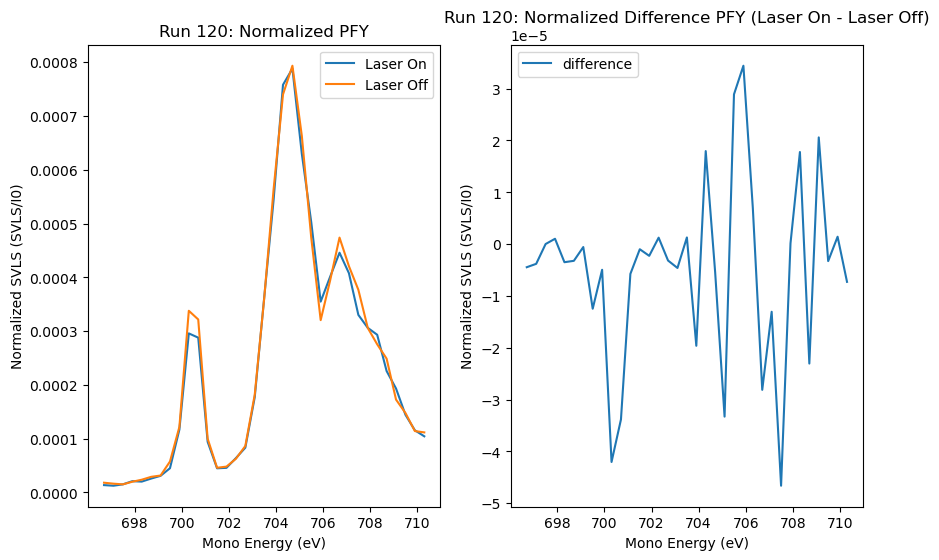

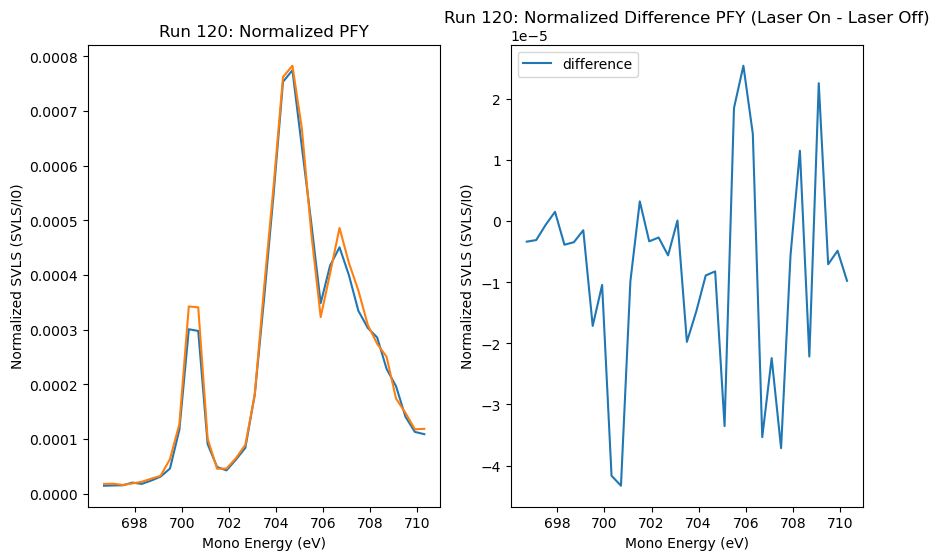

[270. 421. 415. 432. 438. 417. 424. 417. 415. 415. 420. 416. 415. 411.
 423. 392. 432. 412. 406. 422. 416. 401. 411. 405. 409. 403. 398. 422.
 397. 407. 398. 404. 401. 393. 396.]
[263. 284. 267. 295. 285. 290. 292. 281. 273. 302. 291. 285. 282. 277.
 287. 333. 288. 284. 281. 284. 266. 350. 363. 280. 278. 282. 313. 288.
 353. 320. 301. 274. 329. 316. 365.]
[275. 418. 416. 435. 435. 415. 429. 414. 417. 415. 417. 417. 415. 412.
 421. 394. 433. 409. 403. 427. 414. 401. 411. 405. 409. 405. 401. 422.
 393. 407. 396. 409. 398. 390. 398.]
[269. 281. 275. 312. 298. 275. 301. 277. 289. 297. 287. 288. 284. 265.
 280. 313. 291. 299. 269. 295. 293. 349. 368. 281. 282. 270. 292. 300.
 378. 260. 316. 276. 311. 336. 320.]


In [40]:
run_num = 120
counts_on, counts_on_filtered, counts_off, counts_off_filtered, PFY_on_mean, PFY_on_mean_filtered, PFY_off_mean, PFY_off_mean_filtered, scanvar = reduce(run_num=run_num, bg_run_num=86, sigma_tresh=1, num_bins=35)

print(counts_on.shape)
print(counts_on_filtered.shape)
print(counts_off.shape)
print(counts_off_filtered.shape)
print(PFY_on_mean.shape)
print(PFY_on_mean_filtered.shape)
print(PFY_off_mean.shape)
print(PFY_off_mean_filtered.shape)
print(scanvar.shape)

fig, ax = plt.subplots(1, 2, figsize=(10, 6))
ax[0].plot(scanvar, PFY_on_mean_filtered, markersize=0.5, label='Laser On')
ax[0].plot(scanvar, PFY_off_mean_filtered, markersize=0.5, label='Laser Off')
ax[0].set_title(f'Run {run_num}: Normalized PFY')
ax[0].set_xlabel('Mono Energy (eV)')
ax[0].set_ylabel('Normalized SVLS (SVLS/I0)')
ax[0].legend()

ax[1].plot(scanvar, PFY_on_mean_filtered - PFY_off_mean_filtered, markersize=0.5, label='difference')
ax[1].set_title(f'Run {run_num}: Normalized Difference PFY (Laser On - Laser Off)')
ax[1].set_xlabel('Mono Energy (eV)')
ax[1].set_ylabel('Normalized SVLS (SVLS/I0)')
ax[1].legend()
plt.show()


# plot out the normal spectrum before removing any shots
fig1, ax1 = plt.subplots(1, 2, figsize=(10, 6))
ax1[0].plot(scanvar, PFY_on_mean, markersize=0.5, label='Laser On')
ax1[0].plot(scanvar, PFY_off_mean, markersize=0.5, label='Laser Off')
ax1[0].set_title(f'Run {run_num}: Normalized PFY')
ax1[0].set_xlabel('Mono Energy (eV)')
ax1[0].set_ylabel('Normalized SVLS (SVLS/I0)')

ax1[1].plot(scanvar, PFY_on_mean - PFY_off_mean, markersize=0.5, label='difference')
ax1[1].set_title(f'Run {run_num}: Normalized Difference PFY (Laser On - Laser Off)')
ax1[1].set_xlabel('Mono Energy (eV)')
ax1[1].set_ylabel('Normalized SVLS (SVLS/I0)')
ax1[1].legend()
plt.show()

print(counts_on)
print(counts_on_filtered)
print(counts_off)
print(counts_off_filtered)

### Averaging Function for multiple Runs

In [ ]:
def average(runs):
    """
    Function to compute the average of a list of runs.
    This function should take a list of runs and compute the average
    across all runs. Return the averaged data.
    
    1. Reduce each run
    2. PFY_avg = loop over runs (PFY * count) / total count         this way everything is binned according to the total count, ensuring proper normalization across runs.
    3. return the averaged PFY spectrums
    """
    n_runs, n_bins = len(runs), 35
    counts_on_runs = np.zeros((n_runs, n_bins))
    counts_off_runs = np.zeros((n_runs, n_bins))
    PFY_on_mean_runs = np.zeros((n_runs, n_bins))
    PFY_off_mean_runs = np.zeros((n_runs, n_bins))
    counts_on_filtered_runs = np.zeros((n_runs, n_bins))
    counts_off_filtered_runs = np.zeros((n_runs, n_bins))
    PFY_on_mean_filtered_runs = np.zeros((n_runs, n_bins))
    PFY_off_mean_filtered_runs = np.zeros((n_runs, n_bins))
    
    print("--- start reducing the runs ---")
    ## reduce all the runs
    for idx, i in enumerate(runs):
        counts_on, counts_on_filtered, counts_off, counts_off_filtered, PFY_on_mean, PFY_on_mean_filtered, PFY_off_mean, PFY_off_mean_filtered, scanvar = reduce(run_num=i, bg_run_num=86, sigma_tresh=1.75, num_bins=35, n_sigma = 9)
        counts_on_runs[idx] = counts_on
        counts_off_runs[idx] = counts_off
        PFY_on_mean_runs[idx] = PFY_on_mean
        PFY_off_mean_runs[idx] = PFY_off_mean
        counts_on_filtered_runs[idx] = counts_on_filtered
        counts_off_filtered_runs[idx] = counts_off_filtered
        PFY_on_mean_filtered_runs[idx] = PFY_on_mean_filtered
        PFY_off_mean_filtered_runs[idx] = PFY_off_mean_filtered
        print(f"--- finished reducing run {i} ---")
        
    ## weighted average the PFY
    PFY_on_mean_avg = ((PFY_on_mean_runs * counts_on_runs).sum(axis=0) / counts_on_runs.sum(axis=0))
    PFY_off_mean_avg = ((PFY_off_mean_runs * counts_off_runs).sum(axis=0) / counts_off_runs.sum(axis=0))
    PFY_on_mean_filtered_avg = ((PFY_on_mean_filtered_runs * counts_on_filtered_runs).sum(axis=0) / counts_on_filtered_runs.sum(axis=0))
    PFY_off_mean_filtered_avg = ((PFY_off_mean_filtered_runs * counts_off_filtered_runs).sum(axis=0) / counts_off_filtered_runs.sum(axis=0))    

    return PFY_on_mean_avg, PFY_on_mean_filtered_avg, PFY_off_mean_avg, PFY_off_mean_filtered_avg, scanvar
    

In [62]:
runs = [112,114,115,116,117,118,119,120,121,122,123,127,129,138,139,140,141,145]
PFY_on_mean_avg, PFY_on_mean_filtered_avg, PFY_off_mean_avg, PFY_off_mean_filtered_avg, scanvar = average(runs)


--- start reducing the runs ---
  h5 read: 0.6s
  despeckle [on]: kernel=3, n_sigma=9 -> flagged 39 px (0.140%)
  despeckle [off]: kernel=3, n_sigma=9 -> flagged 29 px (0.104%)
  despeckle [on_filtered]: kernel=3, n_sigma=9 -> flagged 13 px (0.047%)
  despeckle [off_filtered]: kernel=3, n_sigma=9 -> flagged 20 px (0.072%)
  processing: 0.9s
run 112: 1.5s, peak RSS 3.2 GB
--- finished reducing run 112 ---
  h5 read: 0.7s
  despeckle [on]: kernel=3, n_sigma=9 -> flagged 27 px (0.097%)
  despeckle [off]: kernel=3, n_sigma=9 -> flagged 23 px (0.083%)
  despeckle [on_filtered]: kernel=3, n_sigma=9 -> flagged 31 px (0.111%)
  despeckle [off_filtered]: kernel=3, n_sigma=9 -> flagged 39 px (0.140%)
  processing: 0.9s
run 114: 1.6s, peak RSS 3.2 GB
--- finished reducing run 114 ---
  h5 read: 0.6s
  despeckle [on]: kernel=3, n_sigma=9 -> flagged 34 px (0.122%)
  despeckle [off]: kernel=3, n_sigma=9 -> flagged 34 px (0.122%)
  despeckle [on_filtered]: kernel=3, n_sigma=9 -> flagged 23 px (0.083%

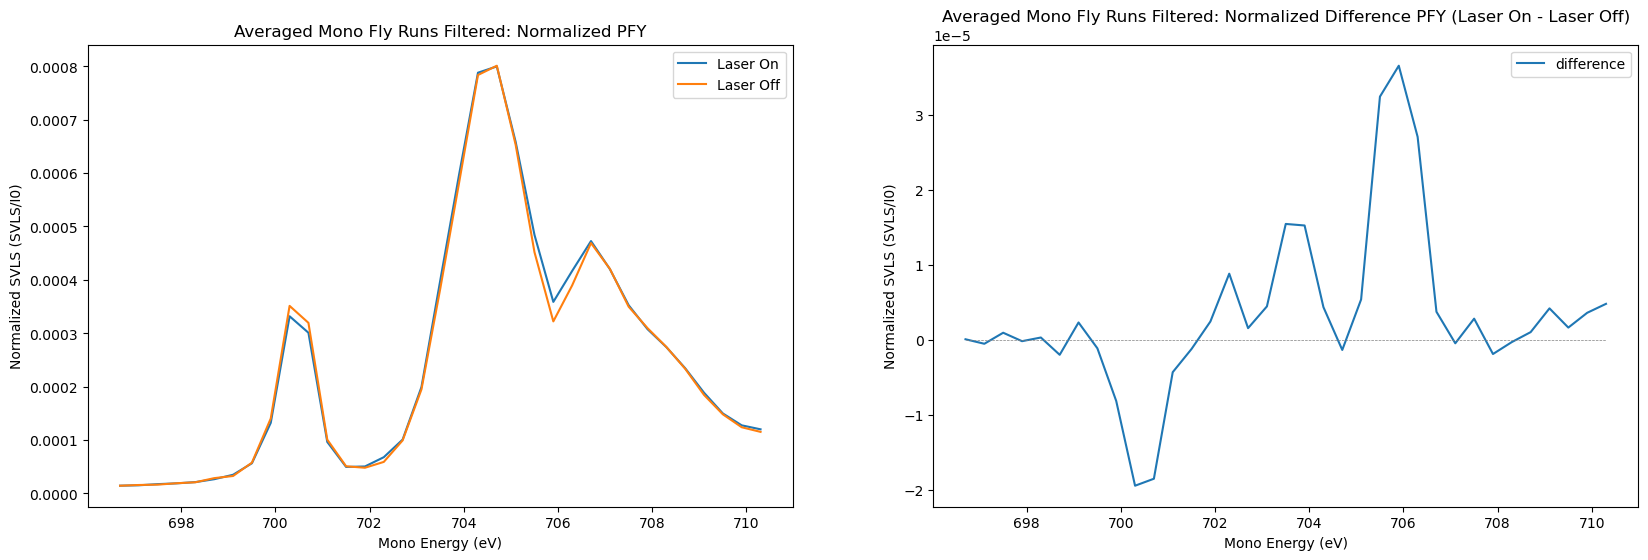

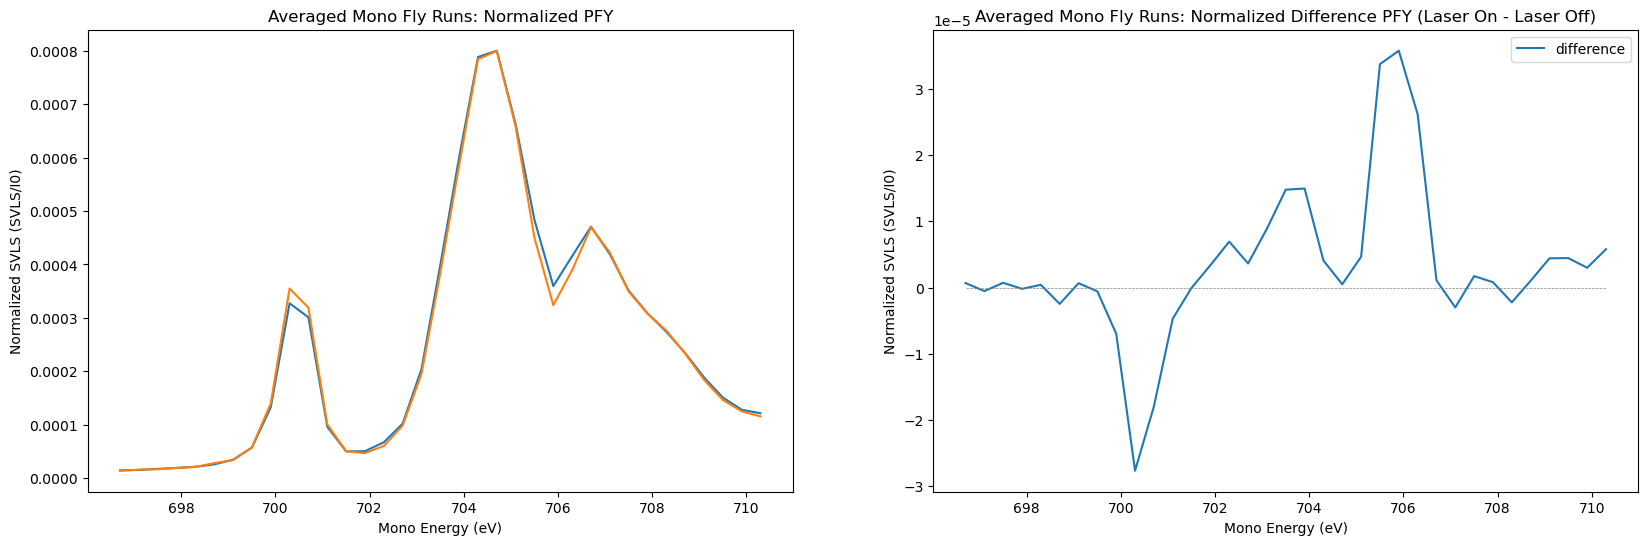

In [63]:
fig, ax = plt.subplots(1, 2, figsize=(20, 6))
ax[0].plot(scanvar, PFY_on_mean_filtered_avg, markersize=0.5, label='Laser On')
ax[0].plot(scanvar, PFY_off_mean_filtered_avg, markersize=0.5, label='Laser Off')
ax[0].set_title(f'Averaged Mono Fly Runs Filtered: Normalized PFY')
ax[0].set_xlabel('Mono Energy (eV)')
ax[0].set_ylabel('Normalized SVLS (SVLS/I0)')
ax[0].legend()

ax[1].plot(scanvar, PFY_on_mean_filtered_avg - PFY_off_mean_filtered_avg, markersize=0.5, label='difference')
ax[1].hlines(0, scanvar[0], scanvar[-1], colors='gray', linestyles='dashed', linewidth=0.5)
ax[1].set_title(f'Averaged Mono Fly Runs Filtered: Normalized Difference PFY (Laser On - Laser Off)')
ax[1].set_xlabel('Mono Energy (eV)')
ax[1].set_ylabel('Normalized SVLS (SVLS/I0)')
ax[1].legend()
plt.show()


# plot out the normal spectrum before removing any shots
fig1, ax1 = plt.subplots(1, 2, figsize=(20, 6))
ax1[0].plot(scanvar, PFY_on_mean_avg, markersize=0.5, label='Laser On')
ax1[0].plot(scanvar, PFY_off_mean_avg, markersize=0.5, label='Laser Off')
ax1[0].set_title(f'Averaged Mono Fly Runs: Normalized PFY')
ax1[0].set_xlabel('Mono Energy (eV)')
ax1[0].set_ylabel('Normalized SVLS (SVLS/I0)')

ax1[1].plot(scanvar, PFY_on_mean_avg - PFY_off_mean_avg, markersize=0.5, label='difference')
ax1[1].set_title(f'Averaged Mono Fly Runs: Normalized Difference PFY (Laser On - Laser Off)')
ax1[1].set_xlabel('Mono Energy (eV)')
ax1[1].set_ylabel('Normalized SVLS (SVLS/I0)')
ax1[1].legend()
ax1[1].hlines(0, scanvar[0], scanvar[-1], colors='gray', linestyles='dashed', linewidth=0.5)
plt.show()

### Troubleshooting

{'axis_svls_off_mean': (35, 796), 'axis_svls_off_std': (35, 796), 'axis_svls_off_sum': (35, 796), 'axis_svls_off_sumI0': (35,), 'axis_svls_off_sumSV': (35, 796), 'axis_svls_on_mean': (35, 796), 'axis_svls_on_std': (35, 796), 'axis_svls_on_sum': (35, 796), 'axis_svls_on_sumI0': (35,), 'axis_svls_on_sumSV': (35, 796), 'counts_off': (35,), 'counts_on': (35,), 'fzp_off_mean': (35,), 'fzp_off_std': (35,), 'fzp_off_sum': (35,), 'fzp_on_mean': (35,), 'fzp_on_std': (35,), 'fzp_on_sum': (35,), 'scanvar_off': (35,), 'scanvar_on': (35,)}
ref n_bins: (35,)  yours: (35,)
ref energies: [696.7 697.1 697.5 697.9 698.3] ... [708.7 709.1 709.5 709.9 710.3]
your centers: [696.7 697.1 697.5 697.9 698.3] ... [708.7 709.1 709.5 709.9 710.3]
ref on/off shot counts: [275. 418. 416. 435. 435.] [270. 421. 415. 432. 438.]


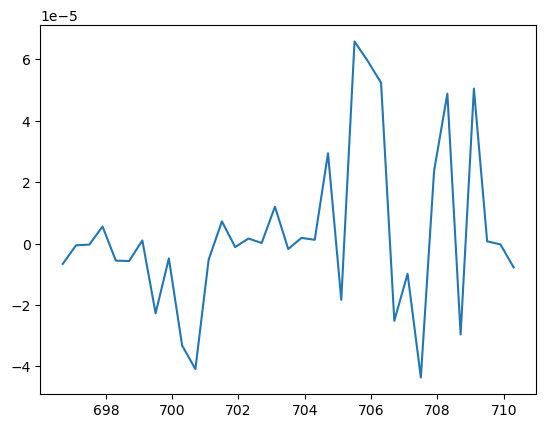

In [83]:
import h5py
with h5py.File('./proc/Run0120.h5', 'r') as f:
    ref_on_SV  = f['axis_svls_on_sumSV'][:]
    ref_on_I0  = f['axis_svls_on_sumI0'][:]
    ref_off_SV = f['axis_svls_off_sumSV'][:]
    ref_off_I0 = f['axis_svls_off_sumI0'][:]
    sv_on      = f['scanvar_on'][:]
    print({k: f[k].shape for k in f.keys()})
    print("ref n_bins:", ref_on.shape, " yours:", binned_svls_on.shape)
    print("ref energies:", sv_on[:5], "...", sv_on[-5:])
    print("your centers:", bin_centers[:5], "...", bin_centers[-5:])
    print("ref on/off shot counts:", f['counts_on'][:5], f['counts_off'][:5])

ref_on  = ref_on_SV.sum(axis=-1)  / ref_on_I0
ref_off = ref_off_SV.sum(axis=-1) / ref_off_I0
plt.plot(sv_on, ref_on - ref_off)     # does this reproduce the good spectrum?

### Transmission spectrum

In [ ]:
fzp_on = np.zeros(num_bins)
fzp_off = np.zeros(num_bins)

fzp_norm = fzp_proj / I0_int


for i in num_bins:
    on_mask = bin_idx == i & laser_on
    off_mask = bin_idx == i & laser_off
    
    fzp_on[i] = fzp_norm[on_mask].mean()
    fzp_off[i] = fzp_norm[off_mask].mean()


fig, ax = plt.subplots(1, 2 , figsize = (10,16))
ax[0].plot(bin_centers, fzp_on, label = "Laser On")
ax[0].plot(bin_centers, fzp_off, label = "Laser Off")
ax[0].set_title(f'Run {run}: Normalized Transmission')
ax[0].set_xlabel('Mono Energy (eV)')
ax[0].set_ylabel('Normalized Transmission(fzp/I0)')

ax[1].plot(bin_centers, fzp_on - fzp_off)
ax[0].set_title(f'Run {run}: XANES from Transmission')
ax[0].set_xlabel('Mono Energy (eV)')
ax[0].set_ylabel('Normalized Difference in Transmission(fzp/I0)')



### Playing with masking to understand the flow of masking

In [24]:
data = np.array([1, 2,3, 4, 5, 6,7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20])
# mask takes all even values
mask_1 = data %  2 == 0
# mask 2 takes all multiple of 3
mask_2 = data % 3 == 0

# now store the indices of those masks
indices_mask_1 = np.flatnonzero(mask_1)
print(mask_1, indices_mask_1)

# now combine masks and get the indices of the combined mask
combined_mask = mask_1 & mask_2

print(combined_mask, np.flatnonzero(combined_mask))

[False  True False  True False  True False  True False  True False  True
 False  True False  True False  True False  True] [ 1  3  5  7  9 11 13 15 17 19]
[False False False False False  True False False False False False  True
 False False False False False  True False False] [ 5 11 17]


### Transmission (Andor) Integrated Shots

In [25]:
# check which runs have the andor integrated detector
all_runs = list(range(11, 252))

runs_with_andor = []
for run in all_runs:
    fname = f'{base}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5' 
    try:
        with h5py.File(fname, 'r') as f:
            if 'intg' in f:
                if 'andor_dir' in f['intg'].keys():
                    runs_with_andor.append(run) 
    except OSError as e:
        print(f"Skipping Run {run}: {e}")
        continue

print(runs_with_andor)

Skipping Run 32: Unable to synchronously open file (file is already open for write (may use <h5clear file> to clear file consistency flags))
Skipping Run 177: Unable to synchronously open file (file is already open for write (may use <h5clear file> to clear file consistency flags))
Skipping Run 216: Unable to synchronously open file (file is already open for write (may use <h5clear file> to clear file consistency flags))
[21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84]


In [26]:

# seems like some detector malfunction in the middle of the spectrum, remove points [800:880]
andor_full_no_noise = np.concatenate((andor_full[:,:800], andor_full[:,880:]), axis=1)

andor_proj = andor_full_no_noise.sum(axis=1)
andor_proj = andor_proj.flatten()

plt.figure()
plt.plot(andor_full_no_noise[5000,:])
plt.show()


NameError: name 'andor_full' is not defined

### I0 vs. Transmission (andor dir)

In [ ]:
plt.figure()
plt.scatter(I0_int_laser_on, andor_proj_laser_on, s=0.03)
plt.scatter(I0_int_laser_off, andor_proj_laser_off, s=0.03)
plt.title(f'Run {run}: I0 vs. Transmission')
plt.legend(['Laser On', 'Laser Off'], markerscale = 15)
plt.xlabel('I0')
plt.ylabel('Transmission')
plt.show()

NameError: name 'andor_proj_laser_on' is not defined

<Figure size 640x480 with 0 Axes>